<a href="https://colab.research.google.com/github/Tansu428/dunnhumby-kupon-analizi/blob/main/notebooks/dunnhumby_kupon_analizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dunnhumby: hipotez testleri ve temel modeller (v9)

**v9 değişiklikleri (v8'e göre):** (1) C2d segment kararlılığı (bootstrap Jaccard, geçiş matrisi, hedef kitleye etkisi) ve C2e k=5 karşılaştırması. (2) k seçimi notu `k_selection` sonuçlarına göre düzeltildi (k=4 kararlılığı k=3 ve k=5'ten düşük). (3) E bölümüne hipotez çerçevesi (H0/H1, karar kuralı). (4) Yeni F bölümü: kupon modeli tahmin testi ve çapraz kontrol (AUC ve recall güven aralığı, segment bazında adil recall, churn ve geri dönüş karnesi), Power BI ile aynı BigQuery tablolarından. (5) G0 çıktısı `model_dogrulama_nb` adıyla yazılır; Power BI'daki SQL ile kurulan `model_dogrulama` tablosu korunur. (6) G2'de `WRITE_TO_BQ = False` koruması.

**v8 değişikliği:** G0 hücresi eklendi: `model_dogrulama` tablosu (kupon skoruna göre yarılar), Power BI kampanya sayfasındaki "kuponların yarısı, kullanımın %X'i" grafiğini bu notebook'tan üretir. Sınıflandırma hedefi kupon kullanımıdır (churn bölümü yok).

**v6 değişiklikleri (v5'e göre)**
1. Gelecek harcama penceresi yalnızca tam haftalarla (kesim+1 … son tam hafta) yeniden hesaplanır; 102. hafta kısmi olduğu için dışarıda kalır (bölüm 1, hücre "Gelecek pencere kontrolü").
2. Kupon testi satır ve kullanım sayıları yazdırılır; Power BI sayfa 4 ile aynı olmalı (A1).
3. Sınıflandırma: ek baz çizgiler, doğrusal olmayan kıyas modeli, `C` seçimi ve hane gruplu 5 katlı çapraz doğrulama (A3c).
4. Regresyon: log hedefli Linear Regression, sipariş aralığı özelliği (ablation), RMSE, R² ve "en iyi %20 yakalama" ile 5 katlı CV (B2c).
5. Kümeleme: recency eklenirse ne değişir karşılaştırması (C2b), segment profil kontrolü (C2c). Segmentler değiştirilmez.
6. Apriori: iade satırları hariç, benzersiz çift sayısı, "güçlü kural" eşiği, çeviri sözlüğü; Power BI ile uyumlu `antecedents`/`consequents` sütunları (D1).
7. BigQuery'ye yeni tablolar: `model_metrics`, `k_selection`, `gains_curve`, `calibration`, `household_visit_gaps` (G1, G2).


**Kaynak:** dbt `rpt_` ve `mart_` tabloları (BigQuery `dbt_umitkargaci_dunnhumby`). Kupon testleri dashboard ile aynı tablodan (`rpt_coupon_response`, 13 haftalık pencere) okunur.
**Çıktı:** sonuçlar ve grafik verisi `ml_output` dataset'ine yazılır; Power BI yalnızca bu tabloları gösterir, hesap yapmaz.

Bölümler: 0 kurulum · 1 veri ve çapraz kontrol · A kupon · B gelecek harcama · C segment · D sepet · E özet · G BigQuery'ye yazma (14 tablo).
Testler ilişki ölçer, nedensellik iddiası taşımaz.

## 0. Kurulum

In [ ]:
#@title Paket kurulumu { display-mode: "form" }
!pip install -q mlxtend

In [ ]:
#@title Google yetkisi { display-mode: "form" }
from google.colab import auth
auth.authenticate_user()

In [ ]:
#@title Bağlantı ve yardımcı fonksiyonlar { display-mode: "form" }
import numpy as np
import pandas as pd
from google.cloud import bigquery
from scipy.stats import mannwhitneyu, chi2_contingency, kruskal, spearmanr, chi2 as chi2_dist
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import statsmodels.api as sm

PROJECT = "fifth-howl-508817-h0"
DATASET = "dbt_umitkargaci_dunnhumby"
ML_DATASET = "ml_output"

client = bigquery.Client(project=PROJECT)
pd.set_option("display.max_colwidth", None)

def read_table(name):
    return client.query(f"select * from `{PROJECT}.{DATASET}.{name}`").to_dataframe()

def run_query(sql):
    return client.query(sql).to_dataframe()

In [ ]:
#@title İstatistik yardımcıları { display-mode: "form" }
def cramers_v(table):
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, p, v

def wilson_ci(k, n, z=1.96):
    # Oran için güven aralığı; küçük gruplarda normal yaklaşımdan daha güvenilir
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half

def binned(df, x, y, bins=10):
    # Binscatter: x'i eşit sayılı dilimlere böl, her dilimde y'nin ortalaması
    q = pd.qcut(df[x].rank(method="first"), bins, labels=False)
    g = df.groupby(q).agg(x_mid=(x, "median"), x_mean=(x, "mean"), y_mean=(y, "mean"), y_sum=(y, "sum"),
                          y_std=(y, "std"), n=(y, "size")).reset_index(drop=True)
    g["se"] = g["y_std"] / np.sqrt(g["n"])
    return g

In [ ]:
#@title Grafik ayarları { display-mode: "form" }
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

ACCENT, NEUTRAL, GOOD, RISK = "#1F4E79", "#B0B7C3", "#2E7D32", "#C62828"
INK, MUTED, GRID = "#2B2B2B", "#6B7280", "#E3E6EB"
SEGMENT_PALETTE = ["#2F6DB0", "#D08F1E", "#8A5BB0", "#5BA3D9"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq", ["#F7F8FA", ACCENT])

def segment_color(seg):
    # K 4'ten büyük olursa fazla segmentler nötr gri (renk döngüsü yok)
    return SEGMENT_PALETTE[int(seg)] if int(seg) < len(SEGMENT_PALETTE) else NEUTRAL

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.labelcolor": MUTED, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "lines.linewidth": 2,
})

def fmt_pct(x, d=0):
    return f"%{x * 100:.{d}f}".replace(".", ",")

def fmt_int(n):
    return f"{int(n):,}".replace(",", ".")

def fmt_num(x, d=2):
    return f"{x:.{d}f}".replace(".", ",")

PCT = plt.FuncFormatter(lambda v, _: fmt_pct(v))
PLAIN = plt.FuncFormatter(lambda v, _: fmt_int(v) if v >= 1 else fmt_num(v, 2))

def plain_log_axis(axis):
    axis.set_major_formatter(PLAIN)
    axis.set_minor_formatter(plt.NullFormatter())

def finish(fig, name, note=None):
    if note:
        fig.text(0.01, -0.03, note, color=MUTED, fontsize=8, ha="left", va="top", wrap=True)
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Veri ve çapraz kontrol
Kupon tablosu dashboard'un okuduğu `rpt_coupon_response`. Sansür bayrağı kampanya bitiş gününden üretilir; son veri günü veriden alınır.
CLV'de geçmiş harcama ve iki pay aynı pencereden (17. hafta – kesim haftası) yeniden hesaplanır; ısınma dönemi dışarıda kalır.

In [ ]:
#@title Tabloları BigQuery'den oku { display-mode: "form" }
LAST_DATA_DAY = int(run_query(f"select max(day) as d from `{PROJECT}.{DATASET}.stg_raw__transaction_data`")["d"].iloc[0])

coupon_df = read_table("rpt_coupon_response")
campaign_end = run_query(f"""
    select distinct campaign_id, end_day
    from `{PROJECT}.{DATASET}.rpt_campaign_category`
""")
spend_df = read_table("mart_household_spend_dataset")
cutoff_week = int(spend_df["cutoff_week"].iloc[0])

past_clean = run_query(f"""
    with baskets as (
        select
            household_key,
            sum(sales_value)                                              as past_sales_w17,
            count(distinct basket_id)                                     as past_baskets_w17,
            sum(if(week_no >= {cutoff_week} - 12, sales_value, 0))        as last_13w_sales_w17
        from `{PROJECT}.{DATASET}.mart_fct_baskets`
        where week_no between 17 and {cutoff_week}
        group by household_key
    ),
    brand as (
        select
            t.household_key,
            safe_divide(sum(if(p.brand = 'Private', t.sales_value, 0)), sum(t.sales_value)) as private_brand_share_w17
        from `{PROJECT}.{DATASET}.stg_raw__transaction_data` as t
        join `{PROJECT}.{DATASET}.mart_dim_product` as p
            on t.product_id = p.product_id
        where t.week_no between 17 and {cutoff_week}
          and p.cat not in ('FUEL', 'MISC')
        group by t.household_key
    )
    select
        b.household_key, b.past_sales_w17, b.past_baskets_w17,
        safe_divide(b.last_13w_sales_w17, b.past_sales_w17) as last_13w_sales_share_w17,
        r.private_brand_share_w17
    from baskets as b
    left join brand as r
        on b.household_key = r.household_key
""")

seg_df = read_table("mart_household_segmentation_features")
seg_extra = run_query(f"""
    with brand_share as (
        select
            t.household_key,
            safe_divide(sum(if(p.brand = 'Private', t.sales_value, 0)), sum(t.sales_value)) as private_brand_share
        from `{PROJECT}.{DATASET}.stg_raw__transaction_data` as t
        join `{PROJECT}.{DATASET}.mart_dim_product` as p
            on t.product_id = p.product_id
        where p.cat not in ('FUEL', 'MISC')
        group by t.household_key
    ),
    coupon_ratio as (
        select household_key, avg(cast(has_coupon_disc as int64)) as coupon_basket_ratio
        from `{PROJECT}.{DATASET}.mart_fct_baskets`
        group by household_key
    )
    select b.household_key, b.private_brand_share, c.coupon_basket_ratio
    from brand_share as b
    left join coupon_ratio as c
        on b.household_key = c.household_key
""")

**Gelecek pencere kontrolü.** Veri 711. güne kadar; 102. haftanın yalnızca 4 günü (708–711) var. Kısmi hafta, `future_sales` değerini düşürür ve naive baz çizgiyi (haftalık ortalama × hafta sayısı) şişirir.
Hücre önce dbt'nin `future_sales` değerinin ham sepetlerden yeniden üretilebildiğini doğrular; tutuyorsa gelecek pencereyi son tam haftada keser. Tutmuyorsa durur ve farkı gösterir, dbt modeline müdahale gerekir.

In [ ]:
#@title Gelecek pencere kontrolü { display-mode: "form" }
LAST_FULL_WEEK = LAST_DATA_DAY // 7
horizon_dbt = int(spend_df["horizon_weeks"].iloc[0]) if "horizon_weeks" in spend_df.columns else None

fut = run_query(f"""
    select household_key,
           sum(if(week_no between {cutoff_week + 1} and 102, sales_value, 0)) as fut_all,
           sum(if(week_no between {cutoff_week + 1} and {LAST_FULL_WEEK}, sales_value, 0)) as fut_full
    from `{PROJECT}.{DATASET}.mart_fct_baskets`
    where week_no > {cutoff_week}
    group by household_key
""")
chk = spend_df[["household_key", "future_sales"]].merge(fut, on="household_key", how="left").fillna({"fut_all": 0, "fut_full": 0})
max_diff = float((chk["future_sales"] - chk["fut_all"]).abs().max())
print(f"son tam hafta: {LAST_FULL_WEEK}, dbt ufuk: {horizon_dbt}, dbt future_sales ile ham sepet farkı (maks): {max_diff:.4f}")
assert max_diff < 0.01, "dbt future_sales ham sepetlerden üretilemedi (tanım farkı?). Önce fark nedenini bulun."

if LAST_FULL_WEEK < 102:
    spend_df = spend_df.drop(columns=["future_sales"]).merge(
        chk[["household_key", "fut_full"]].rename(columns={"fut_full": "future_sales"}), on="household_key", how="left")
    spend_df["future_sales"] = spend_df["future_sales"].fillna(0)
spend_df["horizon_weeks"] = min(LAST_FULL_WEEK, 102) - cutoff_week
print(f"gelecek pencere: {cutoff_week + 1}–{min(LAST_FULL_WEEK, 102)}. hafta ({spend_df['horizon_weeks'].iloc[0]} hafta)")

son tam hafta: 101, dbt ufuk: 22, dbt future_sales ile ham sepet farkı (maks): 0.0000
gelecek pencere: 81–101. hafta (21 hafta)


In [ ]:
#@title Birleştir ve hazırla { display-mode: "form" }
coupon_df = coupon_df.merge(campaign_end, on="campaign_id", how="left")
coupon_df["is_censored"] = coupon_df["end_day"] > LAST_DATA_DAY
coupon_df["redeemed"] = coupon_df["redeemed"].astype(bool)

spend_model_df = spend_df.merge(past_clean, on="household_key", how="inner")
spend_model_df = spend_model_df[spend_model_df["past_baskets_w17"] >= 5].reset_index(drop=True)
assert (spend_model_df["past_sales_w17"] > 0).all(), "log için geçmiş harcama sıfırdan büyük olmalı"

seg_df = seg_df.drop(columns=["private_brand_share", "coupon_basket_ratio"], errors="ignore")
seg_df = seg_df.merge(seg_extra, on="household_key", how="left")

pd.Series({"last_data_day": LAST_DATA_DAY, "coupon_rows": len(coupon_df), "censored_rows": int(coupon_df["is_censored"].sum()),
           "missing_end_day": int(coupon_df["end_day"].isna().sum()), "spend_rows": len(spend_model_df), "segment_rows": len(seg_df)})

,0
last_data_day,711
coupon_rows,7208
censored_rows,100
missing_end_day,0
spend_rows,2390
segment_rows,2500


**Çapraz kontrol.** `rpt_coupon_response` ham CSV dosyalarından bağımsız olarak yeniden hesaplanan değerlerle karşılaştırılır (13 haftalık pencere, iade satırları hariç).
İki referans sütunu var: sepetler akaryakıt dahil sayıldıysa birinci, akaryakıtsız sayıldıysa ikinci sütun tutmalı. Tablodaki bütün satırlar bir sütunla eşleşmeli.

In [ ]:
#@title Çapraz kontrol: rpt_coupon_response ve ham veri { display-mode: "form" }
reference = pd.DataFrame({
    "check": ["satır", "kupon kullanan çift", "sum(pre_basket_count)", "penceresinde sepeti olmayan çift",
              "sum(pre_coupon_basket_count)", "kuponlu ürünü önceden alan çift", "TypeA kullanan", "TypeB kullanan", "TypeC kullanan"],
    "ref_all_baskets": [7208, 889, 198499, 27, 12004, 6298, 635, 210, 44],
    "ref_no_fuel": [7208, 889, 179629, 28, 12004, 6298, 635, 210, 44],
})
actual = [
    len(coupon_df),
    int(coupon_df["redeemed"].sum()),
    int(coupon_df["pre_basket_count"].fillna(0).sum()),
    int((coupon_df["pre_basket_count"].fillna(0) == 0).sum()),
    int(coupon_df["pre_coupon_basket_count"].fillna(0).sum()),
    int(coupon_df["bought_coupon_product_before"].astype(bool).sum()),
    int(coupon_df.loc[coupon_df["campaign_type"] == "TypeA", "redeemed"].sum()),
    int(coupon_df.loc[coupon_df["campaign_type"] == "TypeB", "redeemed"].sum()),
    int(coupon_df.loc[coupon_df["campaign_type"] == "TypeC", "redeemed"].sum()),
]
reference["actual"] = actual
reference["match"] = np.where(reference["actual"] == reference["ref_all_baskets"], "akaryakıt dahil",
                     np.where(reference["actual"] == reference["ref_no_fuel"], "akaryakıtsız", "FARKLI"))
reference

,check,ref_all_baskets,ref_no_fuel,actual,match
0,satır,7208,7208,7208,akaryakıt dahil
1,kupon kullanan çift,889,889,889,akaryakıt dahil
2,sum(pre_basket_count),198499,179629,179629,akaryakıtsız
3,penceresinde sepeti olmayan çift,27,28,28,akaryakıtsız
4,sum(pre_coupon_basket_count),12004,12004,12004,akaryakıt dahil
5,kuponlu ürünü önceden alan çift,6298,6298,6298,akaryakıt dahil
6,TypeA kullanan,635,635,635,akaryakıt dahil
7,TypeB kullanan,210,210,210,akaryakıt dahil
8,TypeC kullanan,44,44,44,akaryakıt dahil


`FARKLI` satır varsa testlere geçmeden dur ve tabloyu paylaş. `kuponlu ürünü önceden alan çift` farklıysa tanım farkı olabilir (ör. ürün eşleşmesi kampanya yerine kupon üzerinden); nedenini birlikte kontrol edelim.

## A. Kupon kullanımı (H1–H7)
Hedef: `redeemed`. Kampanya 24 (sansürlü) çıkarılır.
Birincil test: lojistik regresyon, standart hata **hane ve kampanyaya göre** iki yönlü kümelenmiş (bir hane ortalama 4,5 kampanyada; kampanya tipi yalnızca 30 kampanyadan tahmin ediliyor).
Tek değişkenli testler etki büyüklüğünü verir; p-değerleri hane tekrarı nedeniyle tek başına yorumlanmaz.

In [ ]:
#@title A1. Tek değişkenli testler { display-mode: "form" }
test_df = coupon_df[~coupon_df["is_censored"]].copy()
redeemed = test_df["redeemed"]
print(f"kupon testi: {len(test_df):,} gönderim, {int(redeemed.sum())} kullanım, oran {redeemed.mean():.1%} "
      f"(sansürlü kampanyalar çıkarıldı: {int(coupon_df['is_censored'].sum())} satır). Power BI sayfa 4 aynı sayıları göstermeli.")

numeric_vars = {
    "pre_basket_count": "H1 Kupon kullanımı ~ sepet sayısı",
    "pre_sales_value": "H2 Kupon kullanımı ~ toplam harcama",
    "pre_coupon_basket_ratio": "H3 Kupon kullanımı ~ kuponlu sepet oranı",
    "days_since_last_purchase": "H5 Kupon kullanımı ~ son alışverişten geçen gün",
    "pre_discount_depth": "H6 Kupon kullanımı ~ indirim derinliği",
}
categorical_vars = {
    "bought_coupon_product_before": "H4 Kupon kullanımı ~ kuponlu ürünü önceden alma",
    "campaign_type": "H7 Kupon kullanımı ~ kampanya tipi",
}

rows = []
for col, label in numeric_vars.items():
    x1 = test_df.loc[redeemed, col].dropna()
    x0 = test_df.loc[~redeemed, col].dropna()
    u, p = mannwhitneyu(x1, x0, alternative="two-sided")
    rows.append({"hypothesis_id": label.split(" ")[0], "hypothesis": label, "variable": col, "test": "Mann-Whitney U",
                 "summary": f"medyan {x1.median():.2f} (kullanan) vs {x0.median():.2f} (kullanmayan)",
                 "effect": round(2 * u / (len(x1) * len(x0)) - 1, 3), "effect_type": "rank-biserial r", "p_univariate": p})
for col, label in categorical_vars.items():
    table = pd.crosstab(test_df[col], redeemed)
    chi2, p, v = cramers_v(table)
    rates = test_df.groupby(col)["redeemed"].mean().round(3).to_dict()
    rows.append({"hypothesis_id": label.split(" ")[0], "hypothesis": label, "variable": col, "test": "Ki-kare",
                 "summary": f"kullanım oranı {rates}", "effect": round(v, 3), "effect_type": "Cramér's V", "p_univariate": p})
results_a = pd.DataFrame(rows).sort_values("hypothesis_id", key=lambda s: s.str[1:].astype(int)).reset_index(drop=True)
results_a

kupon testi: 7,108 gönderim, 882 kullanım, oran 12.4% (sansürlü kampanyalar çıkarıldı: 100 satır). Power BI sayfa 4 aynı sayıları göstermeli.


,hypothesis_id,hypothesis,variable,test,summary,effect,effect_type,p_univariate
0,H1,H1 Kupon kullanımı ~ sepet sayısı,pre_basket_count,Mann-Whitney U,medyan 21.00 (kullanan) vs 19.00 (kullanmayan),0.088,rank-biserial r,2.071313e-05
1,H2,H2 Kupon kullanımı ~ toplam harcama,pre_sales_value,Mann-Whitney U,medyan 821.44 (kullanan) vs 632.73 (kullanmayan),0.243,rank-biserial r,1.453408e-31
2,H3,H3 Kupon kullanımı ~ kuponlu sepet oranı,pre_coupon_basket_ratio,Mann-Whitney U,medyan 0.14 (kullanan) vs 0.00 (kullanmayan),0.497,rank-biserial r,6.429015e-140
3,H4,H4 Kupon kullanımı ~ kuponlu ürünü önceden alma,bought_coupon_product_before,Ki-kare,"kullanım oranı {np.False_: 0.025, np.True_: 0.139}",0.114,Cramér's V,7.843412e-22
4,H5,H5 Kupon kullanımı ~ son alışverişten geçen gün,days_since_last_purchase,Mann-Whitney U,medyan 3.00 (kullanan) vs 3.00 (kullanmayan),-0.116,rank-biserial r,1.898852e-08
5,H6,H6 Kupon kullanımı ~ indirim derinliği,pre_discount_depth,Mann-Whitney U,medyan 0.17 (kullanan) vs 0.15 (kullanmayan),0.218,rank-biserial r,1.051796e-25
6,H7,H7 Kupon kullanımı ~ kampanya tipi,campaign_type,Ki-kare,"kullanım oranı {'TypeA': 0.16, 'TypeB': 0.079, 'TypeC': 0.077}",0.121,Cramér's V,1.702982e-23


In [ ]:
#@title A2. Kümelenmiş lojistik regresyon (birincil test) { display-mode: "form" }
model_cols = ["pre_basket_count", "pre_sales_value", "pre_coupon_basket_ratio",
              "days_since_last_purchase", "pre_discount_depth"]
logit_df = test_df.dropna(subset=model_cols + ["bought_coupon_product_before", "campaign_type"]).copy()

for col in ["pre_basket_count", "pre_sales_value", "days_since_last_purchase"]:
    logit_df[col + "_t"] = np.log1p(logit_df[col])
for col in ["pre_coupon_basket_ratio", "pre_discount_depth"]:
    logit_df[col + "_t"] = logit_df[col]
for col in model_cols:
    logit_df[col + "_z"] = (logit_df[col + "_t"] - logit_df[col + "_t"].mean()) / logit_df[col + "_t"].std()

logit_df["y"] = logit_df["redeemed"].astype(int)
logit_df["bought_before"] = logit_df["bought_coupon_product_before"].astype(int)
groups_2way = np.column_stack([pd.factorize(logit_df["household_key"])[0], pd.factorize(logit_df["campaign_id"])[0]])

formula = ("y ~ pre_basket_count_z + pre_sales_value_z + pre_coupon_basket_ratio_z"
           " + days_since_last_purchase_z + pre_discount_depth_z + bought_before"
           " + C(campaign_type, Treatment(reference='TypeB'))")
logit_fit = smf.logit(formula, data=logit_df).fit(disp=False, cov_type="cluster", cov_kwds={"groups": groups_2way})

ci = logit_fit.conf_int()
results_a2 = pd.DataFrame({"odds_ratio": np.exp(logit_fit.params), "ci_low": np.exp(ci[0]),
                           "ci_high": np.exp(ci[1]), "p_value": logit_fit.pvalues}).drop(index="Intercept").round(4)

# Her hipotez için birincil p: kümelenmiş modeldeki terimin Wald testi (H7: iki tip katsayısı birlikte)
wald = logit_fit.wald_test_terms(skip_single=False, scalar=True).table
term_map = {"H1": "pre_basket_count_z", "H2": "pre_sales_value_z", "H3": "pre_coupon_basket_ratio_z", "H4": "bought_before",
            "H5": "days_since_last_purchase_z", "H6": "pre_discount_depth_z", "H7": "C(campaign_type, Treatment(reference='TypeB'))"}
results_a["p_value"] = results_a["hypothesis_id"].map(lambda h: float(wald.loc[term_map[h], "pvalue"]))
results_a["test"] = results_a["test"] + " + kümelenmiş lojistik (birincil p)"
print(f"model satırı: {len(logit_df)}  (dışarıda kalan, penceresinde sepeti olmayan çift: {len(test_df) - len(logit_df)})")
results_a2

model satırı: 7080  (dışarıda kalan, penceresinde sepeti olmayan çift: 28)


,odds_ratio,ci_low,ci_high,p_value
"C(campaign_type, Treatment(reference='TypeB'))[T.TypeA]",3.1374,2.1344,4.6118,0.0000
"C(campaign_type, Treatment(reference='TypeB'))[T.TypeC]",0.9303,0.6956,1.2440,0.6259
pre_basket_count_z,1.0877,0.9283,1.2745,0.2986
pre_sales_value_z,1.6330,1.3273,2.0091,0.0000
pre_coupon_basket_ratio_z,2.0007,1.7930,2.2326,0.0000
days_since_last_purchase_z,0.8808,0.7794,0.9952,0.0417
pre_discount_depth_z,1.1789,1.0482,1.3258,0.0060
bought_before,2.7655,1.5868,4.8195,0.0003


In [ ]:
#@title A3. Temel model: Logistic Regression { display-mode: "form" }
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

feature_cols = [c + "_t" for c in model_cols] + ["bought_before"]
X = pd.concat([logit_df[feature_cols],
               pd.get_dummies(logit_df["campaign_type"], prefix="type", drop_first=True, dtype=int)], axis=1)
y = logit_df["y"]
groups = logit_df["household_key"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, y_train)
proba = clf.predict_proba(X_test)[:, 1]

coupon_scores = logit_df[["household_key", "campaign_id"]].copy()
coupon_scores["score"] = clf.predict_proba(X)[:, 1]
coupon_scores["score_decile"] = pd.qcut(coupon_scores["score"].rank(method="first"), 10, labels=False) + 1
coupon_scores["is_test_set"] = False
coupon_scores.iloc[test_idx, coupon_scores.columns.get_loc("is_test_set")] = True

pd.Series({
    "common_households": len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])),
    "test_rows": len(test_idx), "base_rate": round(y_test.mean(), 3),
    "roc_auc": round(roc_auc_score(y_test, proba), 3), "pr_auc": round(average_precision_score(y_test, proba), 3),
})

,0
common_households,0.000
test_rows,1304.000
base_rate,0.115
roc_auc,0.792
pr_auc,0.398


In [ ]:
#@title A3b. Zamana göre train/test ve baseline kıyası { display-mode: "form" }
from sklearn.metrics import brier_score_loss

# Kampanyaları bitiş gününe göre sırala: ilk ~%80 eğitim, son kampanyalar test
ce = campaign_end.drop_duplicates("campaign_id").set_index("campaign_id")["end_day"]
logit_df["end_day"] = logit_df["campaign_id"].map(ce)
camp_order = (logit_df.groupby("campaign_id").agg(end_day=("end_day", "first"), n=("y", "size"))
              .sort_values("end_day").reset_index())
camp_order["cum_share"] = camp_order["n"].cumsum() / camp_order["n"].sum()
test_camps = set(camp_order.loc[camp_order["cum_share"] > 0.8, "campaign_id"])
is_test = logit_df["campaign_id"].isin(test_camps).values
assert logit_df.loc[~is_test, "end_day"].max() <= logit_df.loc[is_test, "end_day"].max()

X_tr, X_te = X.loc[~is_test], X.loc[is_test]
y_tr, y_te = y.loc[~is_test], y.loc[is_test]

def fit_lr(cols):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr[cols], y_tr)

def evaluate(name, p, y_true):
    k = max(1, int(0.2 * len(y_true)))
    top = np.argsort(-p)[:k]
    return {"model": name,
            "roc_auc": round(roc_auc_score(y_true, p), 3),
            "pr_auc": round(average_precision_score(y_true, p), 3),
            "brier": round(brier_score_loss(y_true, p), 4),
            "en_iyi_%20_yakalama": round(float(y_true.values[top].sum() / y_true.sum()), 3)}

type_cols = [c for c in X.columns if c.startswith("type_")]
full_clf = fit_lr(list(X.columns))
p_full = full_clf.predict_proba(X_te)[:, 1]

results_lr = [
    evaluate("taban oran (sabit tahmin)", np.full(len(y_te), y_tr.mean()), y_te),
    evaluate("yalnızca kampanya tipi", fit_lr(type_cols).predict_proba(X_te[type_cols])[:, 1], y_te),
    evaluate("tek değişken: kuponlu sepet oranı",
             fit_lr(["pre_coupon_basket_ratio_t"]).predict_proba(X_te[["pre_coupon_basket_ratio_t"]])[:, 1], y_te),
    evaluate("tam model (zaman bazlı ayrım)", p_full, y_te),
    evaluate("tam model (haneye göre rastgele, önceki)", proba, y_test),
]
print(f"eğitim: {(~is_test).sum()} satır, test: {is_test.sum()} satır, test kampanya sayısı: {len(test_camps)}, "
      f"test taban oranı: {y_te.mean():.3f}")

# Hane düzeyinde bootstrap ile AUC güven aralığı
hh_te = logit_df.loc[is_test, "household_key"].values
rng = np.random.default_rng(42)
uniq = np.unique(hh_te)
idx_by_hh = {h: np.where(hh_te == h)[0] for h in uniq}
boot = []
for _ in range(300):
    pick = np.concatenate([idx_by_hh[h] for h in rng.choice(uniq, len(uniq), replace=True)])
    if y_te.values[pick].min() != y_te.values[pick].max():
        boot.append(roc_auc_score(y_te.values[pick], p_full[pick]))
print(f"tam model ROC AUC %95 aralık: {np.percentile(boot, 2.5):.3f} – {np.percentile(boot, 97.5):.3f}")

# A4-4 ve BigQuery çıktısı yeni ayrımı kullansın
proba, y_test = p_full, y_te
coupon_scores["score"] = full_clf.predict_proba(X)[:, 1]
coupon_scores["score_decile"] = pd.qcut(coupon_scores["score"].rank(method="first"), 10, labels=False) + 1
coupon_scores["is_test_set"] = is_test

model_metrics_lr = pd.DataFrame(results_lr)
model_metrics_lr

eğitim: 4982 satır, test: 2098 satır, test kampanya sayısı: 7, test taban oranı: 0.145
tam model ROC AUC %95 aralık: 0.770 – 0.828


,model,roc_auc,pr_auc,brier,en_iyi_%20_yakalama
0,taban oran (sabit tahmin),0.500,0.145,0.1247,0.069
1,yalnızca kampanya tipi,0.599,0.178,0.1226,0.102
2,tek değişken: kuponlu sepet oranı,0.769,0.366,0.1111,0.536
3,tam model (zaman bazlı ayrım),0.801,0.468,0.1016,0.559
4,"tam model (haneye göre rastgele, önceki)",0.792,0.398,0.0856,0.567


In [ ]:
#@title A3c. Ek baz çizgiler, kıyas modeli, C seçimi ve çapraz doğrulama { display-mode: "form" }
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_score

hh_train = set(logit_df.loc[~is_test, "household_key"]); hh_test = set(logit_df.loc[is_test, "household_key"])
print(f"zaman bazlı ayrımda hem eğitimde hem testte görünen hane: {len(hh_train & hh_test)} / test hanesi {len(hh_test)}")

# C seçimi: yalnızca eğitim kümesinde, hane gruplu CV
groups_tr = logit_df.loc[~is_test, "household_key"].values
c_rows = []
for c_val in [0.01, 0.1, 1, 10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=c_val))
    auc = cross_val_score(m, X_tr, y_tr, groups=groups_tr, cv=GroupKFold(5), scoring="roc_auc")
    c_rows.append({"C": c_val, "cv_auc_mean": round(auc.mean(), 3), "cv_auc_sd": round(auc.std(), 3)})
c_table = pd.DataFrame(c_rows)
best_C = float(c_table.sort_values("cv_auc_mean", ascending=False)["C"].iloc[0])

tuned = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=best_C)).fit(X_tr, y_tr)
bb = ["bought_before"]
hgb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42).fit(X_tr, y_tr)
extra = [
    evaluate("yalnızca ürünü önceden alma", fit_lr(bb).predict_proba(X_te[bb])[:, 1], y_te),
    evaluate(f"tam model (C={best_C:g})", tuned.predict_proba(X_te)[:, 1], y_te),
    evaluate("HistGradientBoosting (kıyas)", hgb.predict_proba(X_te)[:, 1], y_te),
]
model_metrics_lr = pd.concat([model_metrics_lr, pd.DataFrame(extra)], ignore_index=True)

# Hane gruplu 5 katlı CV (tüm veri, tam model)
cv_auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=best_C)),
                         X, y, groups=groups, cv=GroupKFold(5), scoring="roc_auc")
print(f"hane gruplu 5 katlı CV ROC AUC: {cv_auc.round(3)}  ortalama {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")
display(c_table)
model_metrics_lr

zaman bazlı ayrımda hem eğitimde hem testte görünen hane: 1107 / test hanesi 1207
hane gruplu 5 katlı CV ROC AUC: [0.776 0.811 0.788 0.81  0.771]  ortalama 0.791 ± 0.017


,C,cv_auc_mean,cv_auc_sd
0,0.01,0.787,0.023
1,0.10,0.784,0.024
2,1.00,0.783,0.024
3,10.00,0.783,0.024


,model,roc_auc,pr_auc,brier,en_iyi_%20_yakalama
0,taban oran (sabit tahmin),0.500,0.145,0.1247,0.069
1,yalnızca kampanya tipi,0.599,0.178,0.1226,0.102
2,tek değişken: kuponlu sepet oranı,0.769,0.366,0.1111,0.536
3,tam model (zaman bazlı ayrım),0.801,0.468,0.1016,0.559
4,"tam model (haneye göre rastgele, önceki)",0.792,0.398,0.0856,0.567
5,yalnızca ürünü önceden alma,0.528,0.152,0.1236,0.270
6,tam model (C=0.01),0.803,0.463,0.1036,0.566
7,HistGradientBoosting (kıyas),0.801,0.481,0.0997,0.576


### A4. Görseller (başlıklar sonuç geldikten sonra bulguya göre yeniden yazılır)

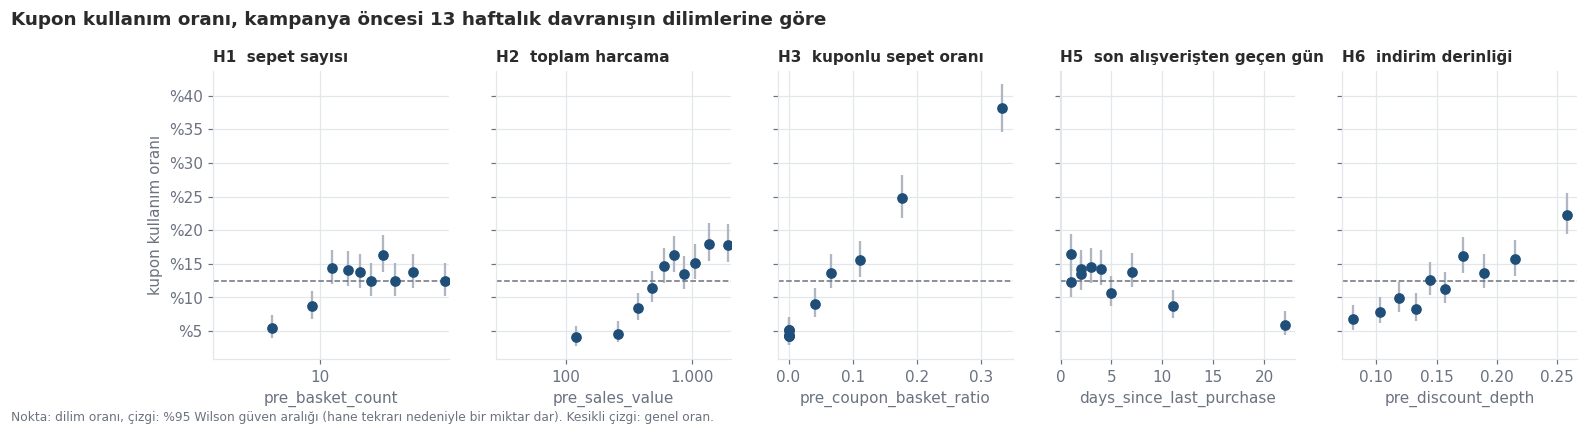

In [ ]:
#@title A4-1. Binscatter (H1, H2, H3, H5, H6) { display-mode: "form" }
base_rate = test_df["redeemed"].mean()
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), sharey=True)
for ax, (col, label) in zip(axes, numeric_vars.items()):
    d = test_df.dropna(subset=[col]).assign(y=lambda t: t["redeemed"].astype(int))
    g = binned(d, col, "y", bins=10)
    low, high = wilson_ci(g["y_sum"], g["n"])
    ax.errorbar(g["x_mid"], g["y_mean"], yerr=[g["y_mean"] - low, high - g["y_mean"]],
                fmt="o", color=ACCENT, ecolor=NEUTRAL, elinewidth=1.5, capsize=0, markersize=6)
    ax.axhline(base_rate, color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(label.split(" ", 1)[0] + "  " + label.split("~ ")[1], fontsize=10)
    ax.set_xlabel(col)
    if col in ["pre_basket_count", "pre_sales_value"]:
        ax.set_xscale("symlog", linthresh=1)
        plain_log_axis(ax.xaxis)
axes[0].set_ylabel("kupon kullanım oranı")
axes[0].yaxis.set_major_formatter(PCT)
fig.suptitle("Kupon kullanım oranı, kampanya öncesi 13 haftalık davranışın dilimlerine göre", x=0.01, ha="left",
             fontweight="bold", color=INK, y=1.04)
finish(fig, "a4_1_binscatter", "Nokta: dilim oranı, çizgi: %95 Wilson güven aralığı (hane tekrarı nedeniyle bir miktar dar). Kesikli çizgi: genel oran.")

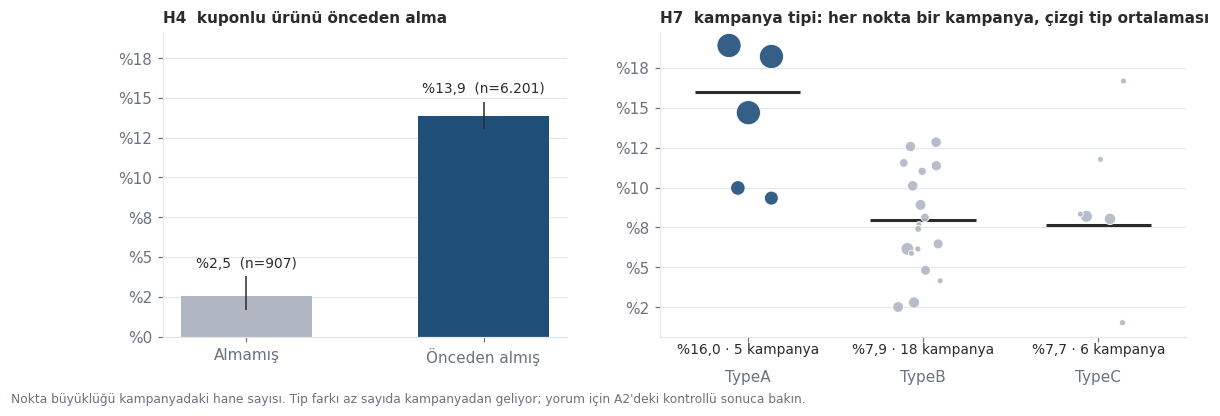

In [ ]:
#@title A4-2. H4 ve H7 (kampanya düzeyinde) { display-mode: "form" }
camp = test_df.groupby(["campaign_id", "campaign_type"])["redeemed"].agg(["sum", "size"]).reset_index()
camp["rate"] = camp["sum"] / camp["size"]
types = ["TypeA", "TypeB", "TypeC"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
ax = axes[0]
g = test_df.groupby("bought_coupon_product_before")["redeemed"].agg(["sum", "size"]).reset_index()
g["rate"] = g["sum"] / g["size"]
low, high = wilson_ci(g["sum"], g["size"])
labels = ["Almamış" if not v else "Önceden almış" for v in g["bought_coupon_product_before"]]
ax.bar(labels, g["rate"], color=[ACCENT if r == g["rate"].max() else NEUTRAL for r in g["rate"]], width=0.55,
       yerr=[g["rate"] - low, high - g["rate"]], error_kw=dict(ecolor=INK, elinewidth=1))
for x_i, (r, n) in enumerate(zip(g["rate"], g["size"])):
    ax.text(x_i, high[x_i] + 0.004, f"{fmt_pct(r, 1)}  (n={fmt_int(n)})", ha="center", va="bottom", color=INK, fontsize=9)
ax.set_ylim(0, np.max(high) * 1.3)
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis="x", visible=False)
ax.set_title("H4  kuponlu ürünü önceden alma", fontsize=10)

ax = axes[1]
rng = np.random.default_rng(1)
for i, t in enumerate(types):
    d = camp[camp["campaign_type"] == t]
    xs = i + rng.uniform(-0.15, 0.15, len(d))
    ax.scatter(xs, d["rate"], s=np.clip(d["size"] / 4, 15, 250), color=ACCENT if t == "TypeA" else NEUTRAL,
               edgecolors="white", linewidths=0.6, alpha=0.9, zorder=3)
    type_rate = d["sum"].sum() / d["size"].sum()
    ax.hlines(type_rate, i - 0.3, i + 0.3, color=INK, linewidth=2)
    ax.text(i, -0.02, f"{fmt_pct(type_rate, 1)} · {len(d)} kampanya", ha="center", va="top", fontsize=9, color=INK,
            transform=ax.get_xaxis_transform())
ax.set_xticks(range(len(types)), types)
ax.tick_params(axis="x", pad=18)
ax.set_xlim(-0.5, len(types) - 0.5)
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis="x", visible=False)
ax.set_title("H7  kampanya tipi: her nokta bir kampanya, çizgi tip ortalaması", fontsize=10)
finish(fig, "a4_2_bought_before_and_type", "Nokta büyüklüğü kampanyadaki hane sayısı. Tip farkı az sayıda kampanyadan geliyor; yorum için A2'deki kontrollü sonuca bakın.")

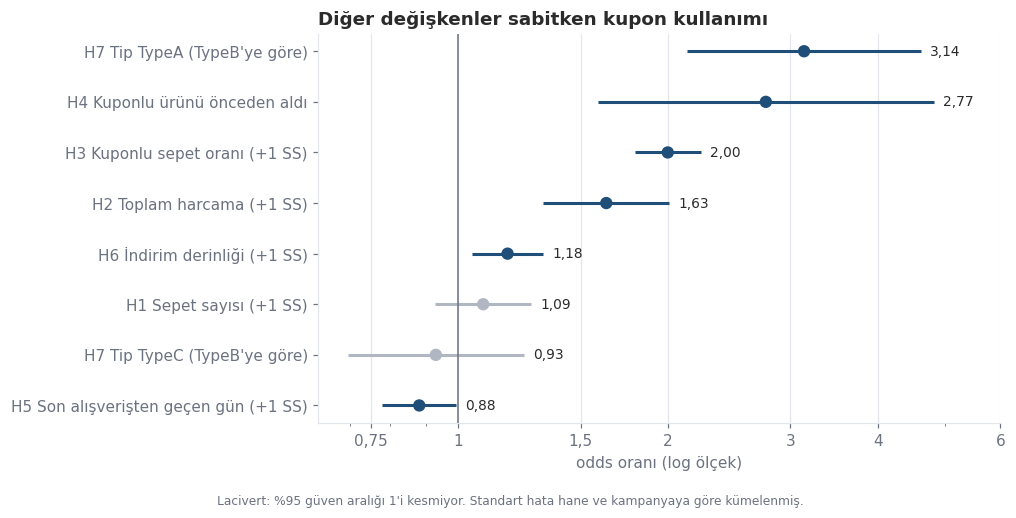

In [ ]:
#@title A4-3. Odds oranı grafiği { display-mode: "form" }
pretty = {
    "pre_basket_count_z": "H1 Sepet sayısı (+1 SS)", "pre_sales_value_z": "H2 Toplam harcama (+1 SS)",
    "pre_coupon_basket_ratio_z": "H3 Kuponlu sepet oranı (+1 SS)", "bought_before": "H4 Kuponlu ürünü önceden aldı",
    "days_since_last_purchase_z": "H5 Son alışverişten geçen gün (+1 SS)", "pre_discount_depth_z": "H6 İndirim derinliği (+1 SS)",
}
forest = results_a2.copy()
forest.index = [pretty.get(i, i.replace("C(campaign_type, Treatment(reference='TypeB'))[T.", "H7 Tip ").replace("]", " (TypeB'ye göre)"))
                for i in forest.index]
forest = forest.sort_values("odds_ratio")
sig = (forest["ci_low"] > 1) | (forest["ci_high"] < 1)
colors = [ACCENT if s else NEUTRAL for s in sig]

fig, ax = plt.subplots(figsize=(8, 0.45 * len(forest) + 1))
ypos = np.arange(len(forest))
ax.hlines(ypos, forest["ci_low"], forest["ci_high"], color=colors, linewidth=2)
ax.scatter(forest["odds_ratio"], ypos, color=colors, s=50, zorder=3)
ax.axvline(1, color=MUTED, linewidth=1)
for y_i, (o, hi) in enumerate(zip(forest["odds_ratio"], forest["ci_high"])):
    ax.text(hi * 1.03, y_i, fmt_num(o), va="center", fontsize=9, color=INK)
ax.set_xscale("log")
ticks = [t for t in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8] if forest["ci_low"].min() * 0.9 <= t <= forest["ci_high"].max() * 1.3]
ax.set_xticks(ticks, [fmt_num(t, 2).rstrip("0").rstrip(",") for t in ticks])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(ypos, forest.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("odds oranı (log ölçek)")
ax.set_title("Diğer değişkenler sabitken kupon kullanımı")
finish(fig, "a4_3_odds_ratio_forest", "Lacivert: %95 güven aralığı 1'i kesmiyor. Standart hata hane ve kampanyaya göre kümelenmiş.")

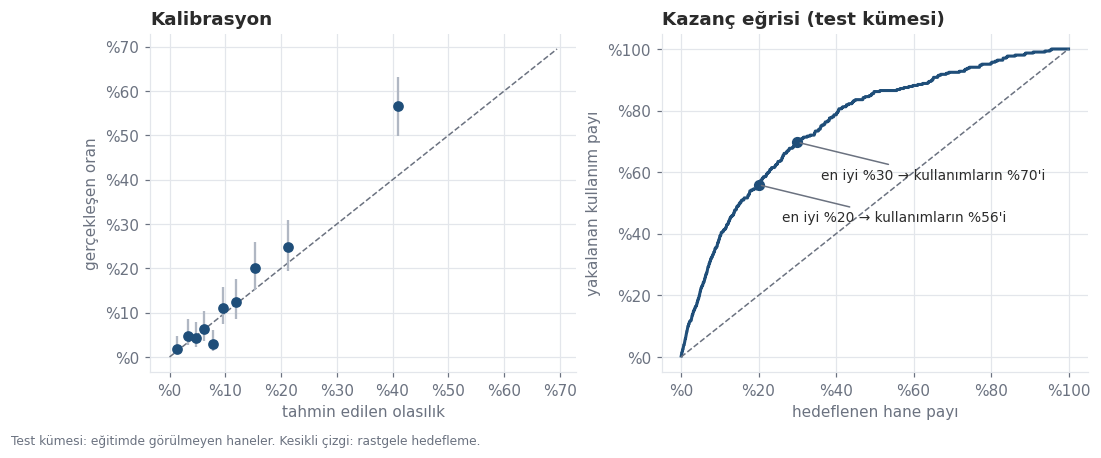

In [ ]:
#@title A4-4. Kalibrasyon ve kazanç eğrisi { display-mode: "form" }
eval_df = pd.DataFrame({"y": y_test.values, "p": proba})
eval_df["decile"] = pd.qcut(eval_df["p"].rank(method="first"), 10, labels=False)
calib = eval_df.groupby("decile").agg(pred=("p", "mean"), obs=("y", "mean"), k=("y", "sum"), n=("y", "size"))
low, high = wilson_ci(calib["k"], calib["n"])
ranked = eval_df.sort_values("p", ascending=False).reset_index(drop=True)
share_targeted = (np.arange(len(ranked)) + 1) / len(ranked)
share_captured = ranked["y"].cumsum() / ranked["y"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
lim = max(calib["pred"].max(), np.max(high)) * 1.1
ax.plot([0, lim], [0, lim], color=MUTED, linestyle="--", linewidth=1)
ax.errorbar(calib["pred"], calib["obs"], yerr=[calib["obs"] - low, high - calib["obs"]], fmt="o", color=ACCENT, ecolor=NEUTRAL, elinewidth=1.5, markersize=6)
ax.set_xlabel("tahmin edilen olasılık"); ax.set_ylabel("gerçekleşen oran"); ax.set_title("Kalibrasyon")
ax = axes[1]
ax.plot(share_targeted, share_captured, color=ACCENT)
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
for t in [0.2, 0.3]:
    c = share_captured[int(t * len(ranked)) - 1]
    ax.scatter([t], [c], color=ACCENT, s=40, zorder=3)
    ax.annotate(f"en iyi {fmt_pct(t)} → kullanımların {fmt_pct(c)}'i", (t, c), xytext=(t + 0.06, c - 0.12),
                fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
for a in axes:
    a.xaxis.set_major_formatter(PCT); a.yaxis.set_major_formatter(PCT)
ax.set_xlabel("hedeflenen hane payı"); ax.set_ylabel("yakalanan kullanım payı"); ax.set_title("Kazanç eğrisi (test kümesi)")
finish(fig, "a4_4_calibration_gains", "Test kümesi: eğitimde görülmeyen haneler. Kesikli çizgi: rastgele hedefleme.")

## B. Gelecek harcama (H9–H11)
Hedef: `future_sales` (kesim haftasından sonraki ufuk). Açıklayıcı değişkenlerin üçü de aynı pencereden: 17. hafta – kesim haftası.

In [ ]:
#@title B1. Spearman ve PPML (birincil test) { display-mode: "form" }
regression_vars = {
    "past_sales_w17": "H9 Gelecek harcama ~ geçmiş harcama",
    "last_13w_sales_share_w17": "H10 Gelecek harcama ~ son 13 haftanın harcama payı",
    "private_brand_share_w17": "H11 Gelecek harcama ~ market markası payı",
}
reg_features = list(regression_vars)
reg_df = spend_model_df.dropna(subset=reg_features + ["future_sales"]).copy()

rows = []
for col, label in regression_vars.items():
    rho, p = spearmanr(reg_df[col], reg_df["future_sales"])
    rows.append({"hypothesis_id": label.split(" ")[0], "hypothesis": label, "variable": col,
                 "test": "Spearman + PPML (birincil p)", "summary": "", "effect": round(rho, 3), "effect_type": "rho", "p_univariate": p})
results_b = pd.DataFrame(rows)

reg_df["log_past_sales"] = np.log(reg_df["past_sales_w17"])
ppml_fit = smf.glm("future_sales ~ log_past_sales + last_13w_sales_share_w17 + private_brand_share_w17",
                   data=reg_df, family=sm.families.Poisson()).fit(cov_type="HC1")
ci = ppml_fit.conf_int()
results_b3 = pd.DataFrame({"coef": ppml_fit.params, "ci_low": ci[0], "ci_high": ci[1], "p_value": ppml_fit.pvalues}).drop(index="Intercept").round(4)
ppml_term = {"H9": "log_past_sales", "H10": "last_13w_sales_share_w17", "H11": "private_brand_share_w17"}
results_b["p_value"] = results_b["hypothesis_id"].map(lambda h: float(ppml_fit.pvalues[ppml_term[h]]))
results_b3

,coef,ci_low,ci_high,p_value
log_past_sales,0.8663,0.8369,0.8957,0.0000
last_13w_sales_share_w17,2.1368,1.9341,2.3394,0.0000
private_brand_share_w17,-0.3394,-0.5821,-0.0968,0.0061


In [ ]:
#@title B2. Temel model: Linear Regression, PPML ve naif kıyas { display-mode: "form" }
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

horizon_weeks = int(spend_model_df["horizon_weeks"].iloc[0])
past_weeks = cutoff_week - 16
train_df, test_df_b = train_test_split(reg_df, test_size=0.2, random_state=42)

lin = LinearRegression().fit(train_df[reg_features], train_df["future_sales"])
ppml_train = smf.glm("future_sales ~ log_past_sales + last_13w_sales_share_w17 + private_brand_share_w17",
                     data=train_df, family=sm.families.Poisson()).fit()

def score(y_true, y_pred):
    return {"MAE": round(mean_absolute_error(y_true, y_pred), 1), "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 1),
            "R2": round(r2_score(y_true, y_pred), 3)}

clv_predictions = reg_df[["household_key", "future_sales"]].copy()
clv_predictions["predicted_sales"] = ppml_train.predict(reg_df)
clv_predictions["is_test_set"] = clv_predictions["household_key"].isin(test_df_b["household_key"])

pd.DataFrame({"naive": score(test_df_b["future_sales"], test_df_b["past_sales_w17"] / past_weeks * horizon_weeks),
              "linear_regression": score(test_df_b["future_sales"], lin.predict(test_df_b[reg_features])),
              "ppml": score(test_df_b["future_sales"], ppml_train.predict(test_df_b))})

,naive,linear_regression,ppml
MAE,311.000,304.800,293.000
RMSE,463.500,440.400,430.800
R2,0.713,0.741,0.752


In [ ]:
#@title B2b. Ufuk kontrolü ve 5-fold CV { display-mode: "form" }
from sklearn.model_selection import KFold

horizon_weeks = int(spend_model_df["horizon_weeks"].iloc[0])
past_weeks = cutoff_week - 16

f_ppml = "future_sales ~ log_past_sales + last_13w_sales_share_w17 + private_brand_share_w17"
cv_rows = []
for i, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=42).split(reg_df)):
    a, b = reg_df.iloc[tr], reg_df.iloc[te]
    p_naive = b["past_sales_w17"] / past_weeks * horizon_weeks
    p_lin = LinearRegression().fit(a[reg_features], a["future_sales"]).predict(b[reg_features])
    p_ppml = smf.glm(f_ppml, data=a, family=sm.families.Poisson()).fit().predict(b)
    cv_rows.append({"fold": i,
                    "mae_naive": mean_absolute_error(b["future_sales"], p_naive),
                    "mae_linear": mean_absolute_error(b["future_sales"], p_lin),
                    "mae_ppml": mean_absolute_error(b["future_sales"], p_ppml)})
cv = pd.DataFrame(cv_rows)
cv["fark_naive_ppml"] = cv["mae_naive"] - cv["mae_ppml"]
cv["fark_naive_linear"] = cv["mae_naive"] - cv["mae_linear"]
print(cv.round(1).to_string(index=False))
print(cv[["mae_naive", "mae_linear", "mae_ppml"]].agg(["mean", "std"]).round(1))
print(f"naive'e göre PPML daha iyi: {(cv['fark_naive_ppml'] > 0).sum()}/5 fold, "
      f"ortalama kazanç {cv['fark_naive_ppml'].mean():.1f} ± {cv['fark_naive_ppml'].std() / np.sqrt(5):.1f} (SE)")

 fold  mae_naive  mae_linear  mae_ppml  fark_naive_ppml  fark_naive_linear
    0      311.0       304.8     293.0             18.0                6.3
    1      290.4       268.3     253.4             37.0               22.2
    2      291.8       289.7     267.2             24.7                2.1
    3      274.1       282.0     266.2              7.9               -7.9
    4      280.4       273.0     255.9             24.5                7.4
      mae_naive  mae_linear  mae_ppml
mean      289.6       283.5     267.1
std        14.0        14.5      15.7
naive'e göre PPML daha iyi: 5/5 fold, ortalama kazanç 22.4 ± 4.8 (SE)


In [ ]:
#@title B2c. Log hedef, sipariş aralığı (ablation), RMSE, R² ve en iyi %20 yakalama (5 katlı CV) { display-mode: "form" }
gap_df = run_query(f"""
    with d as (
        select distinct household_key, day
        from `{PROJECT}.{DATASET}.stg_raw__transaction_data`
        where week_no between 17 and {cutoff_week}
    ),
    g as (
        select household_key, day - lag(day) over (partition by household_key order by day) as gap_days
        from d
    )
    select household_key, avg(gap_days) as avg_gap_w17, approx_quantiles(gap_days, 2)[offset(1)] as median_gap_w17,
           count(*) as shop_days_w17
    from g
    group by household_key
""")
reg2 = reg_df.merge(gap_df, on="household_key", how="left")
for c in ["avg_gap_w17", "median_gap_w17"]:
    reg2[c] = reg2[c].fillna(reg2[c].median())
reg2["log_avg_gap"] = np.log1p(reg2["avg_gap_w17"])

def full_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    top = np.argsort(-y_pred)[:max(1, int(0.2 * len(y_true)))]
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred), "top20_capture": float(y_true[top].sum() / y_true.sum())}

f_base = "future_sales ~ log_past_sales + last_13w_sales_share_w17 + private_brand_share_w17"
log_feats = ["log_past_sales", "last_13w_sales_share_w17", "private_brand_share_w17"]
rows_cv = []
for i, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=42).split(reg2)):
    a, b = reg2.iloc[tr], reg2.iloc[te]
    preds = {
        "naive (geçmiş haftalık ort. × ufuk)": b["past_sales_w17"] / past_weeks * horizon_weeks,
        "Linear Regression (ham)": LinearRegression().fit(a[reg_features], a["future_sales"]).predict(b[reg_features]),
        "Linear Regression (log hedef)": np.expm1(LinearRegression().fit(a[log_feats], np.log1p(a["future_sales"])).predict(b[log_feats])),
        "PPML": smf.glm(f_base, data=a, family=sm.families.Poisson()).fit().predict(b),
        "PPML + sipariş aralığı": smf.glm(f_base + " + log_avg_gap", data=a, family=sm.families.Poisson()).fit().predict(b),
    }
    for name, p in preds.items():
        rows_cv.append({"model_variant": name, "fold": i, **full_score(b["future_sales"], p)})
cv_all = pd.DataFrame(rows_cv)
model_metrics_reg = cv_all.groupby("model_variant", sort=False)[["MAE", "RMSE", "R2", "top20_capture"]].mean().round(3).reset_index()
print("Linear Regression (log hedef): expm1 geri dönüşümü ortalamayı hafif düşük tahmin eder; MAE ve sıralama için sorun değil.")
display(cv_all.groupby("model_variant", sort=False)[["MAE", "RMSE", "R2", "top20_capture"]].agg(["mean", "std"]).round(3))
model_metrics_reg

Linear Regression (log hedef): expm1 geri dönüşümü ortalamayı hafif düşük tahmin eder; MAE ve sıralama için sorun değil.


MAE             RMSE             R2  \
                                        mean     std     mean     std   mean   
model_variant                                                                  
naive (geçmiş haftalık ort. × ufuk)  289.563  14.050  447.140  15.298  0.687   
Linear Regression (ham)              283.546  14.465  420.328  12.811  0.725   
Linear Regression (log hedef)        282.457  21.158  432.921  20.735  0.710   
PPML                                 267.135  15.704  399.013  18.627  0.753   
PPML + sipariş aralığı               266.801  15.714  398.335  18.523  0.753   

                                           top20_capture         
                                       std          mean    std  
model_variant                                                    
naive (geçmiş haftalık ort. × ufuk)  0.061         0.476  0.020  
Linear Regression (ham)              0.041         0.484  0.015  
Linear Regression (log hedef)        0.025         0.486  0.018  
PPML                                 0.031         0.489  0.019  
PPML + sipariş aralığı               0.034         0.490  0.019

,model_variant,MAE,RMSE,R2,top20_capture
0,naive (geçmiş haftalık ort. × ufuk),289.563,447.140,0.687,0.476
1,Linear Regression (ham),283.546,420.328,0.725,0.484
2,Linear Regression (log hedef),282.457,432.921,0.710,0.486
3,PPML,267.135,399.013,0.753,0.489
4,PPML + sipariş aralığı,266.801,398.335,0.753,0.490


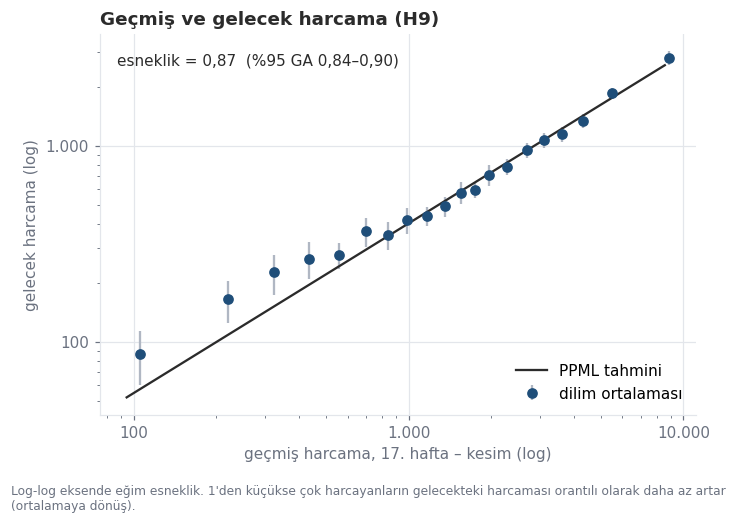

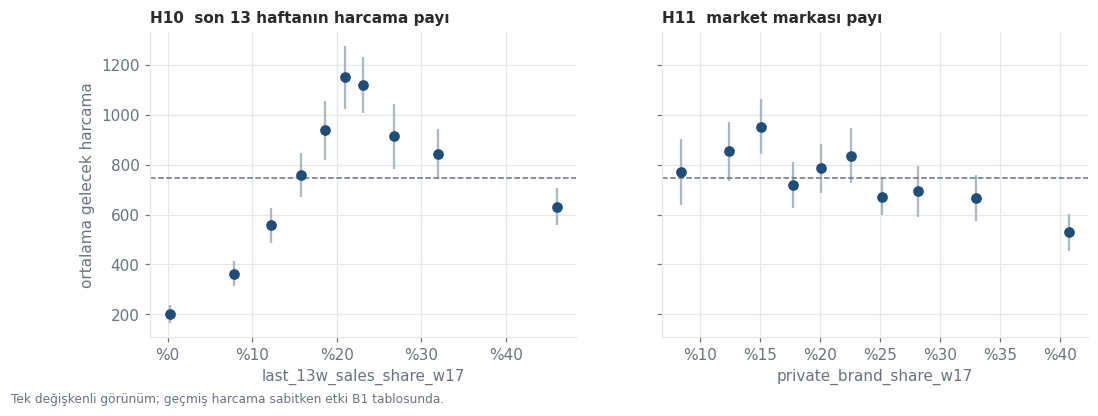

In [ ]:
#@title B3. Görseller (H9, H10, H11) { display-mode: "form" }
g = binned(reg_df, "past_sales_w17", "future_sales", bins=20)
grid = np.exp(np.linspace(np.log(reg_df["past_sales_w17"].quantile(0.02)), np.log(reg_df["past_sales_w17"].quantile(0.98)), 50))
line = ppml_fit.predict(pd.DataFrame({"log_past_sales": np.log(grid),
                                      "last_13w_sales_share_w17": reg_df["last_13w_sales_share_w17"].mean(),
                                      "private_brand_share_w17": reg_df["private_brand_share_w17"].mean()}))
b, lo, hi = results_b3.loc["log_past_sales", ["coef", "ci_low", "ci_high"]]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(g["x_mean"], g["y_mean"], yerr=1.96 * g["se"], fmt="o", color=ACCENT, ecolor=NEUTRAL, elinewidth=1.5, markersize=6, label="dilim ortalaması")
ax.plot(grid, line, color=INK, linewidth=1.5, label="PPML tahmini")
ax.set_xscale("log"); ax.set_yscale("log")
plain_log_axis(ax.xaxis); plain_log_axis(ax.yaxis)
ax.set_xlabel("geçmiş harcama, 17. hafta – kesim (log)"); ax.set_ylabel("gelecek harcama (log)")
ax.set_title("Geçmiş ve gelecek harcama (H9)")
ax.text(0.03, 0.95, f"esneklik = {fmt_num(b)}  (%95 GA {fmt_num(lo)}–{fmt_num(hi)})", transform=ax.transAxes, va="top", color=INK, fontsize=10)
ax.legend(loc="lower right")
finish(fig, "b4_1_past_future_loglog", "Log-log eksende eğim esneklik. 1'den küçükse çok harcayanların gelecekteki harcaması orantılı olarak daha az artar (ortalamaya dönüş).")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col in zip(axes, ["last_13w_sales_share_w17", "private_brand_share_w17"]):
    g = binned(reg_df, col, "future_sales", bins=10)
    ax.errorbar(g["x_mid"], g["y_mean"], yerr=1.96 * g["se"], fmt="o", color=ACCENT, ecolor=NEUTRAL, elinewidth=1.5, markersize=6)
    ax.axhline(reg_df["future_sales"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(PCT)
    ax.set_xlabel(col)
    ax.set_title(regression_vars[col].split(" ", 1)[0] + "  " + regression_vars[col].split("~ ")[1], fontsize=10)
axes[0].set_ylabel("ortalama gelecek harcama")
finish(fig, "b4_2_share_binscatter", "Tek değişkenli görünüm; geçmiş harcama sabitken etki B1 tablosunda.")

## C. Segmentler (H8, H12, H13)
Kümeleme girdisi: harcama, sepet sayısı, ortalama sepet değeri, market markası payı. Kupon oranı ve kategori payları bilinçli olarak dışarıda: girselerdi H8, H12, H13 kendini doğrulardı.
H12 ve H13 **betimleyici**: gruplar veriden türetildiği için p-değeri anlamlı değil; etki büyüklüğü (ε²) raporlanır. H12 kısmen mekaniktir (büyük sepette doğal olarak daha çok kategori olur).

In [ ]:
#@title C1. Özellikler ve k seçimi { display-mode: "form" }
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

seg_features = ["total_sales", "basket_count", "avg_basket_sales", "private_brand_share"]
log_features = ["total_sales", "basket_count", "avg_basket_sales"]
outcome_features = ["avg_categories_per_basket", "fresh_share", "drug_gm_share", "grocery_share"]
profile_extra = [c for c in ["coupon_basket_ratio", "fuel_share"] if c in seg_df.columns]
missing = [c for c in seg_features + outcome_features if c not in seg_df.columns]
assert not missing, f"segment tablosunda olmayan sütunlar: {missing}"

cluster_df = seg_df.dropna(subset=seg_features + outcome_features).copy()
X_seg = cluster_df[seg_features].copy()
for col in log_features:
    X_seg[col] = np.log1p(X_seg[col])
X_seg = StandardScaler().fit_transform(X_seg)

k_scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_seg)
    k_scores.append({"k": k, "inertia": round(km.inertia_, 0), "silhouette": round(silhouette_score(X_seg, km.labels_), 3)})
pd.DataFrame(k_scores)

,k,inertia,silhouette
0,2,6830.0,0.306
1,3,5486.0,0.252
2,4,4743.0,0.235
3,5,4139.0,0.235
4,6,3732.0,0.232
5,7,3420.0,0.230
6,8,3183.0,0.231


In [ ]:
#@title C1b. k seçimi: kararlılık ve ek ölçütler { display-mode: "form" }
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, calinski_harabasz_score

rng = np.random.default_rng(42)
rows_k = []
for k in range(2, 9):
    base = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_seg)
    aris = []
    for b in range(20):
        idx = rng.choice(len(X_seg), len(X_seg), replace=True)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X_seg[idx])
        aris.append(adjusted_rand_score(base.labels_, km_b.predict(X_seg)))
    rows_k.append({"k": k,
                   "silhouette": round(silhouette_score(X_seg, base.labels_), 3),
                   "davies_bouldin": round(davies_bouldin_score(X_seg, base.labels_), 3),
                   "calinski_harabasz": round(calinski_harabasz_score(X_seg, base.labels_), 0),
                   "stability_ari": round(float(np.mean(aris)), 3),
                   "min_segment_size": int(np.bincount(base.labels_).min())})
k_table = pd.DataFrame(rows_k)
k_table

,k,silhouette,davies_bouldin,calinski_harabasz,stability_ari,min_segment_size
0,2,0.306,1.307,1159.0,0.951,910
1,3,0.252,1.284,1027.0,0.893,700
2,4,0.235,1.266,922.0,0.613,411
3,5,0.235,1.218,883.0,0.839,356
4,6,0.232,1.146,838.0,0.683,271
5,7,0.230,1.106,800.0,0.644,266
6,8,0.231,1.152,763.0,0.525,122


**k seçimi (`k_selection` sonuçlarıyla).** Silhouette k ≥ 3'te 0,23–0,25 arasında yatay: veride doğal kümeler yok, müşteriler bir süreklilik üzerinde. k=2 her ölçütte önde (silhouette 0,306, ARI 0,951) ama yalnızca büyük/küçük harcayan ayrımı veriyor, iş yorumu için yetersiz.
**k=4'ün zayıf yanı kararlılık:** bootstrap ARI 0,613; k=3 (0,893) ve k=5 (0,839) daha kararlı. k=5 aynı silhouette'te (0,235) daha kararlı ve Davies-Bouldin'de biraz daha iyi (1,218 / 1,266).
k=4'te kalma gerekçesi: (1) dört profil iş açısından ayrı aksiyonlara karşılık geliyor; (2) kampanya kararı segment etiketine değil hanenin davranışına bağlı (ziyareti düştü mü, kupon puanı yüksek mi). **C2d** kararsızlığın hangi sınırda olduğunu ve hedef kitleyi etkileyip etkilemediğini ölçer; **C2e** k=5'in yeni bir aksiyon getirip getirmediğini gösterir. Segmentler kesin sınır değil, eğilim olarak yorumlanır.

Segment 3'ün kupon verisinde yalnızca 29 satırı var (H8). Sıfır kullanım gözleniyor ama güven aralığı geniş, bu yüzden H15 testine girmiyor. Segment 3 için kupon sonucu çıkarılamaz.

In [ ]:
#@title C2. K-Means ve segment profili { display-mode: "form" }
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_seg)
cluster_df["cluster"] = kmeans.labels_
order = cluster_df.groupby("cluster")["total_sales"].mean().sort_values(ascending=False).index
cluster_df["segment_id"] = cluster_df["cluster"].map({c: i for i, c in enumerate(order)})
household_segments = cluster_df[["household_key", "segment_id"]].copy()

segment_profile = cluster_df.groupby("segment_id")[seg_features + outcome_features + profile_extra].mean().round(3)
segment_profile.insert(0, "households", cluster_df["segment_id"].value_counts().sort_index())
segment_profile

,households,total_sales,basket_count,avg_basket_sales,private_brand_share,avg_categories_per_basket,fresh_share,drug_gm_share,grocery_share,coupon_basket_ratio,fuel_share
segment_id,,,,,,,,,,,
0,749,5872.656,141.127,45.391,0.174,2.198,0.265,0.147,0.562,0.081,0.0
1,701,2996.596,162.789,20.628,0.298,1.845,0.275,0.136,0.571,0.040,0.0
2,639,1358.448,37.358,40.213,0.194,2.108,0.287,0.138,0.552,0.052,0.0
3,411,355.085,26.068,16.294,0.244,1.727,0.274,0.159,0.542,0.023,0.0


Profili inceleyip Sheets'teki `segment_lookup` adlarını bu segment numaralarına göre güncelleyin.

In [ ]:
#@title C2b. Recency eklenirse segmentler ne kadar değişir? (karşılaştırma, segmentler değiştirilmez) { display-mode: "form" }
from sklearn.metrics import adjusted_rand_score
rec = run_query(f"""
    select household_key, {LAST_DATA_DAY} - max(day) as recency_days
    from `{PROJECT}.{DATASET}.stg_raw__transaction_data`
    group by household_key
""")
cmp_df = cluster_df.merge(rec, on="household_key", how="left").dropna(subset=["recency_days"])
Xr = cmp_df[seg_features].copy()
for col in log_features:
    Xr[col] = np.log1p(Xr[col])
Xr["recency_days"] = np.log1p(cmp_df["recency_days"])
Xr = StandardScaler().fit_transform(Xr)
km_r = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xr)
print(f"recency'li k={K}: silhouette {silhouette_score(Xr, km_r.labels_):.3f}  (recency'siz {silhouette_score(X_seg, kmeans.labels_):.3f}); "
      f"mevcut segmentlerle ARI {adjusted_rand_score(cmp_df['segment_id'], km_r.labels_):.3f}")
pd.crosstab(cmp_df["segment_id"], km_r.labels_, rownames=["mevcut segment"], colnames=["recency'li küme"])

recency'li k=4: silhouette 0.197  (recency'siz 0.235); mevcut segmentlerle ARI 0.528


recency'li küme,0,1,2,3
mevcut segment,,,,
0,0,0,149,600
1,528,4,43,126
2,31,75,500,33
3,61,346,4,0


In [ ]:
#@title C2c. Segment adı kontrolü { display-mode: "form" }
# Power BI'daki adlar: 0 Sadık büyük sepet, 1 Sık uğrayan küçük sepet, 2 Seyrek büyük alışveriş, 3 Pasif
# Adlar numaraya bağlı; K-Means yeniden çalışınca sıra değişirse adlar yanlış kayar. Beklenen profil sağlanmıyorsa uyarı verir.
sp = segment_profile
checks = {
    "segment 0 en yüksek toplam satış": sp["total_sales"].idxmax() == 0,
    "segment 3 en düşük toplam satış": sp["total_sales"].idxmin() == 3,
    "segment 1 sepet sayısı > segment 2": sp.loc[1, "basket_count"] > sp.loc[2, "basket_count"],
    "segment 2 ort. sepet > segment 1": sp.loc[2, "avg_basket_sales"] > sp.loc[1, "avg_basket_sales"],
}
for name, ok in checks.items():
    print(("TAMAM  " if ok else "UYARI  ") + name)
if not all(checks.values()):
    print("Profil beklenenden farklı: Power BI'daki segment adlarını (Segment Adı SWITCH) güncelleyin.")

TAMAM  segment 0 en yüksek toplam satış
TAMAM  segment 3 en düşük toplam satış
TAMAM  segment 1 sepet sayısı > segment 2
TAMAM  segment 2 ort. sepet > segment 1


In [ ]:
#@title C2d. Segment kararlılığı: hangi segment, hangi sınırda kararsız? { display-mode: "form" }
from scipy.optimize import linear_sum_assignment

B = 50                                   # bootstrap tekrarı
base_lab = cluster_df["segment_id"].to_numpy()          # 0 Sadık, 1 Sık uğrayan, 2 Seyrek, 3 Pasif
cl2seg = dict(zip(kmeans.labels_, base_lab))            # K-Means küme no -> segment no
rng = np.random.default_rng(42)
n_hh = len(base_lab)
same = np.zeros(n_hh)                                   # hanenin kendi segmentinde kalma sayısı
in_target = np.zeros(n_hh)                              # hedef segmentlerde (0 veya 1) kalma sayısı
trans = np.zeros((K, K))                                # geçiş matrisi: mevcut -> bootstrap
jacc = {s: [] for s in range(K)}

for b in range(B):
    idx = rng.choice(n_hh, n_hh, replace=True)
    km_b = KMeans(n_clusters=K, n_init=10, random_state=b).fit(X_seg[idx])
    lab_b = km_b.predict(X_seg)
    # Bootstrap kümelerini mevcut segmentlerle eşle (en çok örtüşen eşleşme)
    cont = np.zeros((K, K))
    np.add.at(cont, (base_lab, lab_b), 1)
    r, c = linear_sum_assignment(-cont)
    m = dict(zip(c, r))
    mapped = np.array([m[l] for l in lab_b])
    same += mapped == base_lab
    in_target += np.isin(mapped, [0, 1])
    np.add.at(trans, (base_lab, mapped), 1)
    for s in range(K):
        a, bb = base_lab == s, mapped == s
        jacc[s].append((a & bb).sum() / (a | bb).sum())

SEG_NAMES = {0: "Sadık büyük sepet", 1: "Sık uğrayan küçük sepet", 2: "Seyrek büyük alışveriş", 3: "Pasif"}
cluster_df["kararlilik"] = same / B
cluster_df["hedefte_kalma"] = in_target / B

seg_stab = pd.DataFrame({
    "segment": [SEG_NAMES[s] for s in range(K)],
    "hane": [int((base_lab == s).sum()) for s in range(K)],
    "jaccard_ort": [round(np.mean(jacc[s]), 3) for s in range(K)],
    "jaccard_min": [round(np.min(jacc[s]), 3) for s in range(K)],
    "ayni_segmentte_kalma": [round(cluster_df.loc[base_lab == s, "kararlilik"].mean(), 3) for s in range(K)],
    "kararli_hane_payi_80": [round((cluster_df.loc[base_lab == s, "kararlilik"] >= 0.8).mean(), 3) for s in range(K)],
})
seg_stab["yorum"] = np.select([seg_stab["jaccard_ort"] >= 0.85, seg_stab["jaccard_ort"] >= 0.75, seg_stab["jaccard_ort"] >= 0.6],
                              ["çok kararlı", "kararlı", "eğilim (sınırlar oynak)"], "kararsız")

trans_df = pd.DataFrame(trans / trans.sum(axis=1, keepdims=True), index=[SEG_NAMES[s] for s in range(K)],
                        columns=[SEG_NAMES[s] for s in range(K)]).round(3)

# Hedef kitle: segment değişse bile hedef segmentlerde (Sadık veya Sık uğrayan) kalıyor mu?
hk = run_query(f"select household_key, segment_adi, hedef from `{PROJECT}.{ML_DATASET}.hedef_kitle`")
hk = hk.merge(cluster_df[["household_key", "kararlilik", "hedefte_kalma"]], on="household_key", how="left")
hedef_ozet = hk.groupby("hedef").agg(
    hane=("household_key", "size"),
    ayni_segmentte_kalma=("kararlilik", "mean"),
    hedef_segmentlerde_kalma=("hedefte_kalma", "mean"),
    hedefte_kalan_pay_90=("hedefte_kalma", lambda s: (s >= 0.9).mean()),
).round(3)

print("1) Segment bazında kararlılık (Jaccard: ≥0,85 çok kararlı, 0,75–0,85 kararlı, 0,60–0,75 eğilim, <0,60 kararsız)")
display(seg_stab)
print("2) Geçiş matrisi: satırdaki segmentin haneleri bootstrap'te hangi segmente düşüyor (satır toplamı 1)")
display(trans_df)
print("3) Hedef kitle: hedef=True satırı 198 hane. Karar kuralı: hedefte_kalan_pay_90 ≥ 0,90 ise k=4 hedefleme için yeterli.")
hedef_ozet

1) Segment bazında kararlılık (Jaccard: ≥0,85 çok kararlı, 0,75–0,85 kararlı, 0,60–0,75 eğilim, <0,60 kararsız)


,segment,hane,jaccard_ort,jaccard_min,ayni_segmentte_kalma,kararli_hane_payi_80,yorum
0,Sadık büyük sepet,749,0.769,0.435,0.860,0.660,kararlı
1,Sık uğrayan küçük sepet,701,0.746,0.375,0.833,0.586,eğilim (sınırlar oynak)
2,Seyrek büyük alışveriş,639,0.628,0.044,0.691,0.086,eğilim (sınırlar oynak)
3,Pasif,411,0.733,0.207,0.851,0.720,eğilim (sınırlar oynak)


2) Geçiş matrisi: satırdaki segmentin haneleri bootstrap'te hangi segmente düşüyor (satır toplamı 1)


,Sadık büyük sepet,Sık uğrayan küçük sepet,Seyrek büyük alışveriş,Pasif
Sadık büyük sepet,0.860,0.124,0.016,0.000
Sık uğrayan küçük sepet,0.032,0.833,0.116,0.018
Seyrek büyük alışveriş,0.153,0.024,0.691,0.133
Pasif,0.000,0.019,0.130,0.851


3) Hedef kitle: hedef=True satırı 198 hane. Karar kuralı: hedefte_kalan_pay_90 ≥ 0,90 ise k=4 hedefleme için yeterli.


,hane,ayni_segmentte_kalma,hedef_segmentlerde_kalma,hedefte_kalan_pay_90
hedef,,,,
False,1257,0.843,0.922,0.770
True,198,0.856,0.944,0.823


In [ ]:
#@title C2e. k=5 olsaydı ne değişirdi? (karşılaştırma, segmentler değiştirilmez) { display-mode: "form" }
km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_seg)
cmp5 = pd.crosstab(cluster_df["segment_id"].map(SEG_NAMES), km5.labels_, rownames=["k=4 segment"], colnames=["k=5 küme"])
prof5 = cluster_df.assign(k5=km5.labels_).groupby("k5")[seg_features].mean().round(2)
prof5.insert(0, "hane", pd.Series(km5.labels_).value_counts().sort_index().values)
print("Satır: mevcut 4 segment. Sütun: k=5 kümeleri. Hangi segment ikiye bölünüyor, ona bakın.")
display(cmp5)
print("k=5 küme profilleri: yeni küme iş açısından farklı bir aksiyon gerektiriyor mu?")
prof5

Satır: mevcut 4 segment. Sütun: k=5 kümeleri. Hangi segment ikiye bölünüyor, ona bakın.


k=5 küme,0,1,2,3,4
k=4 segment,,,,,
Pasif,4,5,0,56,346
Sadık büyük sepet,12,203,534,0,0
Seyrek büyük alışveriş,580,17,8,23,11
Sık uğrayan küçük sepet,4,415,5,277,0


k=5 küme profilleri: yeni küme iş açısından farklı bir aksiyon gerektiriyor mu?


,hane,total_sales,basket_count,avg_basket_sales,private_brand_share
k5,,,,,
0,600,1372.88,37.75,39.96,0.19
1,640,3675.52,188.45,20.92,0.22
2,547,6493.88,128.88,53.80,0.18
3,356,1880.64,90.88,22.42,0.38
4,357,323.52,23.23,17.00,0.22


In [ ]:
#@title C3. Segment ilişkileri (H8, H12, H13) { display-mode: "form" }
rows = []
segment_vars = {
    "avg_categories_per_basket": ("H12", "H12 Segment ~ sepet büyüklüğü"),
    "fresh_share": ("H13", "H13 Segment ~ taze payı"),
    "drug_gm_share": ("H13", "H13 Segment ~ kişisel bakım payı"),
    "grocery_share": ("H13", "H13 Segment ~ market payı"),
}
for col, (hid, label) in segment_vars.items():
    groups_k = [g[col].dropna() for _, g in cluster_df.groupby("segment_id")]
    h, p = kruskal(*groups_k)
    n = sum(len(g) for g in groups_k)
    medians = cluster_df.groupby("segment_id")[col].median().round(3).to_dict()
    rows.append({"hypothesis_id": hid, "hypothesis": label, "variable": col, "test": "Kruskal-Wallis (betimleyici)",
                 "summary": f"medyan {medians}", "effect": round(h / (n - 1), 3), "effect_type": "epsilon²",
                 "p_univariate": p, "p_value": np.nan})
results_c = pd.DataFrame(rows)

# H8: segment ve kupon kullanımı. Hane tekrarı için permütasyon testi: segment etiketleri HANELER arasında karıştırılır,
# bir hanenin bütün kampanyaları birlikte hareket eder. Sıfır kullanımlı segment olsa da çalışır.
h8_df = test_df.merge(household_segments, on="household_key", how="inner")
h8_y = h8_df["redeemed"].astype(int).values
h8_hh, h8_inv = np.unique(h8_df["household_key"].values, return_inverse=True)
seg_by_hh = h8_df.groupby("household_key")["segment_id"].first().reindex(h8_hh).values.astype(int)
n_seg = int(seg_by_hh.max()) + 1

def chi2_stat(seg_per_row):
    counts = np.bincount(seg_per_row * 2 + h8_y, minlength=n_seg * 2).reshape(n_seg, 2).astype(float)
    counts = counts[counts.sum(axis=1) > 0]
    expected = counts.sum(axis=1, keepdims=True) * counts.sum(axis=0, keepdims=True) / counts.sum()
    return float(((counts - expected) ** 2 / expected).sum())

h8_obs = chi2_stat(seg_by_hh[h8_inv])
rng = np.random.default_rng(42)
h8_perm = np.array([chi2_stat(rng.permutation(seg_by_hh)[h8_inv]) for _ in range(999)])
h8_p = float((1 + (h8_perm >= h8_obs).sum()) / (len(h8_perm) + 1))
v_h8 = np.sqrt(h8_obs / (len(h8_y) * 1))
rates = h8_df.groupby("segment_id")["redeemed"].mean().round(3).to_dict()
results_h8 = pd.DataFrame([{"hypothesis_id": "H8", "hypothesis": "H8 Kupon kullanımı ~ segment", "variable": "segment_id",
                            "test": "Ki-kare, hane düzeyinde permütasyon (999)", "summary": f"kullanım oranı {rates}",
                            "effect": round(v_h8, 3), "effect_type": "Cramér's V", "p_univariate": np.nan, "p_value": h8_p}])
pd.concat([results_c, results_h8], ignore_index=True)

,hypothesis_id,hypothesis,variable,test,summary,effect,effect_type,p_univariate,p_value
0,H12,H12 Segment ~ sepet büyüklüğü,avg_categories_per_basket,Kruskal-Wallis (betimleyici),"medyan {0: 2.183, 1: 1.846, 2: 2.077, 3: 1.706}",0.308,epsilon²,1.082107e-166,NaN
1,H13,H13 Segment ~ taze payı,fresh_share,Kruskal-Wallis (betimleyici),"medyan {0: 0.265, 1: 0.27, 2: 0.274, 3: 0.257}",0.005,epsilon²,5.340347e-03,NaN
2,H13,H13 Segment ~ kişisel bakım payı,drug_gm_share,Kruskal-Wallis (betimleyici),"medyan {0: 0.131, 1: 0.115, 2: 0.112, 3: 0.13}",0.007,epsilon²,7.831138e-04,NaN
3,H13,H13 Segment ~ market payı,grocery_share,Kruskal-Wallis (betimleyici),"medyan {0: 0.567, 1: 0.572, 2: 0.555, 3: 0.557}",0.005,epsilon²,9.416221e-03,NaN
4,H8,H8 Kupon kullanımı ~ segment,segment_id,"Ki-kare, hane düzeyinde permütasyon (999)","kullanım oranı {0: 0.148, 1: 0.096, 2: 0.055, 3: 0.0}",0.094,Cramér's V,NaN,0.001


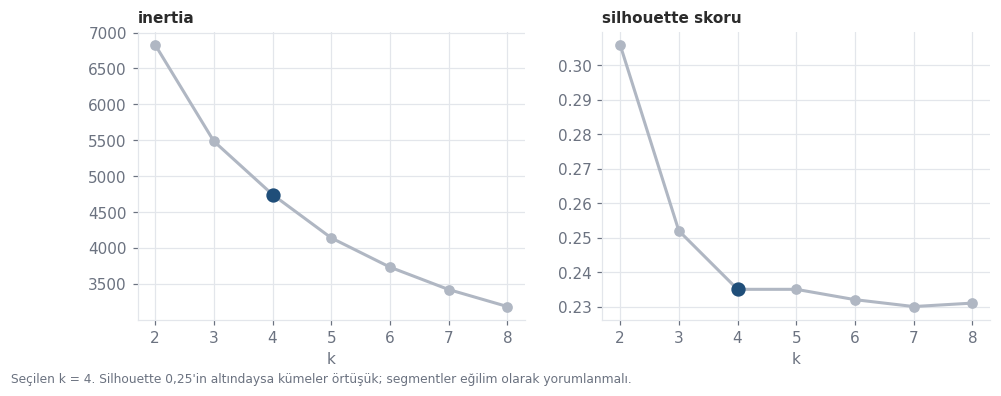

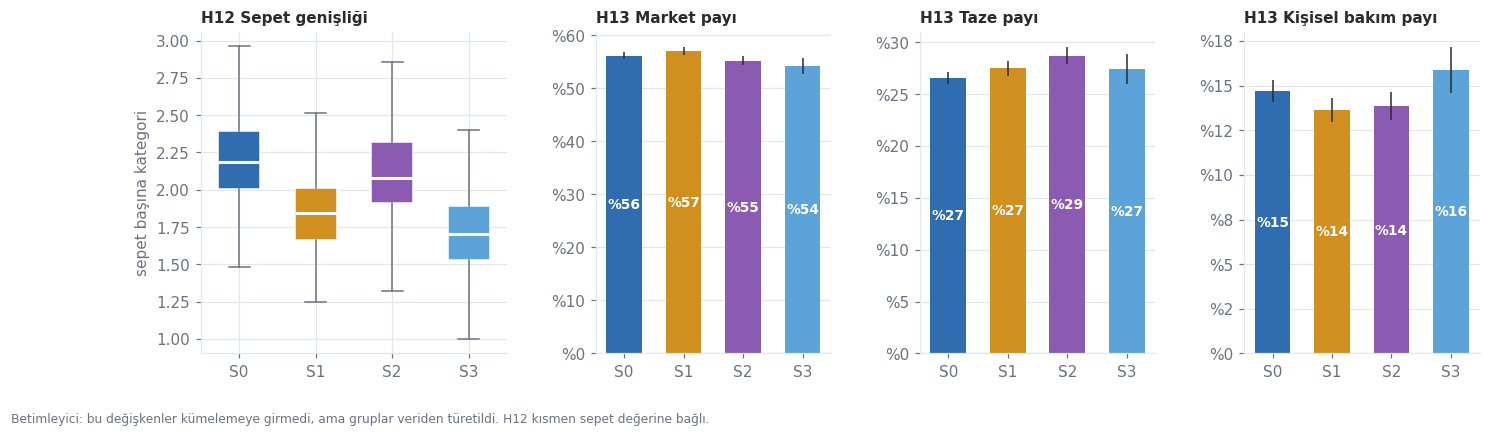

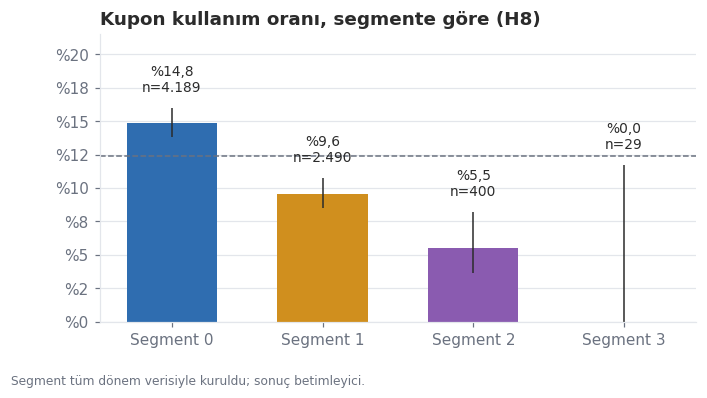

In [ ]:
#@title C4. Görseller { display-mode: "form" }
ks = pd.DataFrame(k_scores)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col, label in zip(axes, ["inertia", "silhouette"], ["inertia", "silhouette skoru"]):
    ax.plot(ks["k"], ks[col], color=NEUTRAL, marker="o", markersize=6)
    ax.scatter(ks.loc[ks["k"] == K, "k"], ks.loc[ks["k"] == K, col], color=ACCENT, s=70, zorder=3)
    ax.set_xlabel("k"); ax.set_title(label, fontsize=10); ax.set_xticks(ks["k"])
finish(fig, "c4_1_k_selection", f"Seçilen k = {K}. Silhouette 0,25'in altındaysa kümeler örtüşük; segmentler eğilim olarak yorumlanmalı.")

seg_ids = sorted(cluster_df["segment_id"].unique())
share_cols = [("grocery_share", "Market payı"), ("fresh_share", "Taze payı"), ("drug_gm_share", "Kişisel bakım payı")]
fig = plt.figure(figsize=(15, 3.8))
gs = fig.add_gridspec(1, 4, width_ratios=[1.3, 1, 1, 1], wspace=0.35)
ax = fig.add_subplot(gs[0])
data = [cluster_df.loc[cluster_df["segment_id"] == s, "avg_categories_per_basket"].dropna() for s in seg_ids]
bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                medianprops=dict(color="white", linewidth=2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, s in zip(bp["boxes"], seg_ids):
    patch.set_facecolor(segment_color(s)); patch.set_edgecolor("white")
ax.set_xticks(range(1, len(seg_ids) + 1), [f"S{s}" for s in seg_ids])
ax.set_title("H12 Sepet genişliği", fontsize=10); ax.set_ylabel("sepet başına kategori")
for i, (col, title) in enumerate(share_cols, start=1):
    ax = fig.add_subplot(gs[i])
    m = cluster_df.groupby("segment_id")[col].agg(["mean", "std", "size"])
    ax.bar([f"S{s}" for s in m.index], m["mean"], color=[segment_color(s) for s in m.index], width=0.6,
           yerr=1.96 * m["std"] / np.sqrt(m["size"]), error_kw=dict(ecolor=INK, elinewidth=1))
    for x_i, v in enumerate(m["mean"]):
        ax.text(x_i, v / 2, fmt_pct(v), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.yaxis.set_major_formatter(PCT); ax.set_title("H13 " + title, fontsize=10); ax.grid(axis="x", visible=False)
finish(fig, "c4_3_segment_profiles", "Betimleyici: bu değişkenler kümelemeye girmedi, ama gruplar veriden türetildi. H12 kısmen sepet değerine bağlı.")

g = h8_df.groupby("segment_id")["redeemed"].agg(["sum", "size"])
g["rate"] = g["sum"] / g["size"]
low, high = wilson_ci(g["sum"], g["size"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar([f"Segment {s}" for s in g.index], g["rate"], color=[segment_color(s) for s in g.index], width=0.6,
       yerr=[g["rate"] - low, high - g["rate"]], error_kw=dict(ecolor=INK, elinewidth=1))
for x_i, (r, n) in enumerate(zip(g["rate"], g["size"])):
    ax.text(x_i, high[x_i] + 0.01, f"{fmt_pct(r, 1)}\nn={fmt_int(n)}", ha="center", va="bottom", fontsize=9, color=INK)
ax.axhline(h8_df["redeemed"].mean(), color=MUTED, linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, np.max(high) * 1.35); ax.grid(axis="x", visible=False)
ax.set_title("Kupon kullanım oranı, segmente göre (H8)")
finish(fig, "c4_4_redeem_by_segment", "Segment tüm dönem verisiyle kuruldu; sonuç betimleyici.")

## D. Sepet (H14, H15)
H14 betimleyici (Apriori, ürün grubu düzeyi, akaryakıt ve MISC hariç).
H15: segmentlerin kupon kullanımı, **sunulan kupona göre** karşılaştırılır. Kupon kategorisi (kampanya, kupon) çiftine göre belirlenir.
Test: Poisson GLM, `kullanım ~ segment × kategori + log(sunulan kupon)`; etkileşim terimi segmentin kategori tercihi sunulandan farklı mı sorusunu test eder.

In [ ]:
#@title D0. Sepet ve kupon verisini oku { display-mode: "form" }
basket_items = run_query(f"""
    select distinct t.basket_id, p.commodity_desc
    from `{PROJECT}.{DATASET}.stg_raw__transaction_data` as t
    join `{PROJECT}.{DATASET}.mart_dim_product` as p
        on t.product_id = p.product_id
    where p.cat not in ('FUEL', 'MISC')
      and p.commodity_desc is not null
      and t.sales_value > 0   -- iade satırları sepete sahte kategori eklemesin
""")
coupon_main = run_query(f"""
    with coupon_cat as (
        select c.campaign as campaign_id, c.coupon_upc, p.cat, count(*) as n
        from `{PROJECT}.{DATASET}.stg_raw__coupon` as c
        join `{PROJECT}.{DATASET}.mart_dim_product` as p
            on c.product_id = p.product_id
        group by 1, 2, 3
    )
    select campaign_id, coupon_upc, cat as coupon_cat
    from coupon_cat
    where true
    qualify row_number() over (partition by campaign_id, coupon_upc order by n desc, cat) = 1
""")
redemptions = run_query(f"""
    select distinct household_key, campaign as campaign_id, coupon_upc
    from `{PROJECT}.{DATASET}.stg_raw__coupon_redempt`
""")

In [ ]:
#@title D1. Apriori (H14) { display-mode: "form" }
from mlxtend.frequent_patterns import apriori, association_rules

basket_codes, basket_index = pd.factorize(basket_items["basket_id"])
item_codes, item_index = pd.factorize(basket_items["commodity_desc"])
matrix = np.zeros((len(basket_index), len(item_index)), dtype=bool)
matrix[basket_codes, item_codes] = True
onehot = pd.DataFrame(matrix, columns=item_index)

MIN_SUPPORT = 0.02
MIN_LIFT = 1.2        # listeye girme eşiği
STRONG_LIFT = 2.0     # "güçlü kural" tanımı (sunumda bu eşik söylenir)
# Kategori adlarını tek dile çevirmek için sözlük: {"CAT FOOD": "Kedi maması", ...}; boşsa adlar olduğu gibi kalır
TRANSLATE = {}
frequent = apriori(onehot, min_support=MIN_SUPPORT, use_colnames=True, max_len=2)
rules = association_rules(frequent, num_itemsets=len(onehot), metric="lift", min_threshold=MIN_LIFT)
tr_name = lambda x: TRANSLATE.get(x, x)
# Power BI'daki ölçüler antecedents/consequents sütunlarını " + " ile birleştirilmiş metin olarak bekler
rules["antecedents"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(tr_name(x) for x in s)))
rules["consequents"] = rules["consequents"].apply(lambda s: " + ".join(sorted(tr_name(x) for x in s)))
association_rules_out = (rules[["antecedents", "consequents", "support", "confidence", "lift"]]
                         .sort_values("lift", ascending=False).reset_index(drop=True))
association_rules_out["pair"] = association_rules_out.apply(
    lambda r: " | ".join(sorted([r["antecedents"], r["consequents"]])), axis=1)
association_rules_out["is_strong"] = association_rules_out["lift"] >= STRONG_LIFT
n_pairs = association_rules_out["pair"].nunique()
n_strong_pairs = association_rules_out.loc[association_rules_out["is_strong"], "pair"].nunique()
print(f"yönlü kural: {len(association_rules_out)}, benzersiz çift: {n_pairs}, güçlü (lift ≥ {STRONG_LIFT:g}) benzersiz çift: {n_strong_pairs}, "
      f"en yüksek lift: {association_rules_out['lift'].max():.2f}")
association_rules_out.round(3).head(20)

yönlü kural: 670, benzersiz çift: 335, güçlü (lift ≥ 2) benzersiz çift: 210, en yüksek lift: 9.81


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift,pair,is_strong
0,DRY NOODLES/PASTA,PASTA SAUCE,0.026,0.458,9.815,DRY NOODLES/PASTA | PASTA SAUCE,True
1,PASTA SAUCE,DRY NOODLES/PASTA,0.026,0.548,9.815,DRY NOODLES/PASTA | PASTA SAUCE,True
2,DELI MEATS,CHEESES,0.028,0.417,9.243,CHEESES | DELI MEATS,True
3,CHEESES,DELI MEATS,0.028,0.630,9.243,CHEESES | DELI MEATS,True
4,DRY BN/VEG/POTATO/RICE,VEGETABLES - SHELF STABLE,0.021,0.404,4.494,DRY BN/VEG/POTATO/RICE | VEGETABLES - SHELF STABLE,True
5,VEGETABLES - SHELF STABLE,DRY BN/VEG/POTATO/RICE,0.021,0.237,4.494,DRY BN/VEG/POTATO/RICE | VEGETABLES - SHELF STABLE,True
6,VEGETABLES - SHELF STABLE,FRUIT - SHELF STABLE,0.021,0.235,4.446,FRUIT - SHELF STABLE | VEGETABLES - SHELF STABLE,True
7,FRUIT - SHELF STABLE,VEGETABLES - SHELF STABLE,0.021,0.400,4.446,FRUIT - SHELF STABLE | VEGETABLES - SHELF STABLE,True
8,VEGETABLES - SHELF STABLE,DRY NOODLES/PASTA,0.022,0.247,4.422,DRY NOODLES/PASTA | VEGETABLES - SHELF STABLE,True
9,DRY NOODLES/PASTA,VEGETABLES - SHELF STABLE,0.022,0.398,4.422,DRY NOODLES/PASTA | VEGETABLES - SHELF STABLE,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
#@title D2. Segment ve kupon kategorisi (H15) { display-mode: "form" }
# Sunulan kupon: hanenin aldığı her kampanyadaki kuponlar (sansürlü kampanya hariç)
pairs = test_df[["household_key", "campaign_id"]].merge(household_segments, on="household_key", how="inner")
offered_by_campaign = coupon_main.groupby(["campaign_id", "coupon_cat"]).size().rename("n_coupons").reset_index()
offered = (pairs.merge(offered_by_campaign, on="campaign_id")
                .groupby(["segment_id", "coupon_cat"])["n_coupons"].sum().rename("offered"))
used = (redemptions.merge(pairs, on=["household_key", "campaign_id"], how="inner")
                   .merge(coupon_main, on=["campaign_id", "coupon_upc"], how="inner")
                   .groupby(["segment_id", "coupon_cat"]).size().rename("redeemed"))
segment_coupon_category = pd.concat([offered, used], axis=1).fillna(0).reset_index()
segment_coupon_category = segment_coupon_category[segment_coupon_category["offered"] > 0]
segment_coupon_category["redeem_rate"] = segment_coupon_category["redeemed"] / segment_coupon_category["offered"]

# Toplam kullanımı 5'ten az olan segment ve kategoriler test dışı (sıfır hücre modeli tanımsız yapar)
seg_tot = segment_coupon_category.groupby("segment_id")["redeemed"].transform("sum")
cat_tot = segment_coupon_category.groupby("coupon_cat")["redeemed"].transform("sum")
glm_df = segment_coupon_category[(seg_tot >= 5) & (cat_tot >= 5)].copy()
excluded = sorted(set(segment_coupon_category["segment_id"]) - set(glm_df["segment_id"]))
glm_df["log_offered"] = np.log(glm_df["offered"])
glm_df["segment"] = glm_df["segment_id"].astype(str)
full = smf.glm("redeemed ~ C(segment) * C(coupon_cat)", data=glm_df, family=sm.families.Poisson(), offset=glm_df["log_offered"]).fit()
reduced = smf.glm("redeemed ~ C(segment) + C(coupon_cat)", data=glm_df, family=sm.families.Poisson(), offset=glm_df["log_offered"]).fit()
lr = 2 * (full.llf - reduced.llf)
dof = full.df_model - reduced.df_model
p_h15 = float(chi2_dist.sf(lr, dof)) if dof > 0 else np.nan
used_table = glm_df.pivot(index="segment_id", columns="coupon_cat", values="redeemed").fillna(0)
_, _, v_h15 = cramers_v(used_table.loc[used_table.sum(axis=1) > 0, used_table.sum(axis=0) > 0])
results_h15 = pd.DataFrame([{"hypothesis_id": "H15", "hypothesis": "H15 Kupon kategorisi ~ segment", "variable": "segment × coupon_cat",
                             "test": "Poisson GLM, sunulan kupon offset, etkileşim LR testi",
                             "summary": f"LR = {lr:.1f}, sd = {dof:.0f}; test dışı segment: {excluded or 'yok'}",
                             "effect": round(v_h15, 3), "effect_type": "Cramér's V", "p_univariate": np.nan, "p_value": p_h15}])
rate_table = segment_coupon_category.pivot(index="segment_id", columns="coupon_cat", values="redeem_rate")
(rate_table * 1000).round(1)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

coupon_cat,DRUG_GM,FRESH,GROCERY,OTHER
segment_id,,,,
0,2.3,6.0,3.7,0.0
1,0.9,2.8,1.6,0.0
2,0.9,1.6,0.9,0.0
3,0.0,0.0,0.0,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Tablo: sunulan her 1.000 kupondan kaç tanesinin kullanıldığı. Toplam kullanımı 5'ten az olan segment ya da kategori teste girmez (özet satırında yazılır). Hane tekrarı toplu tabloda düzeltilemiyor; p-değeri ihtiyatlı okunmalı.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

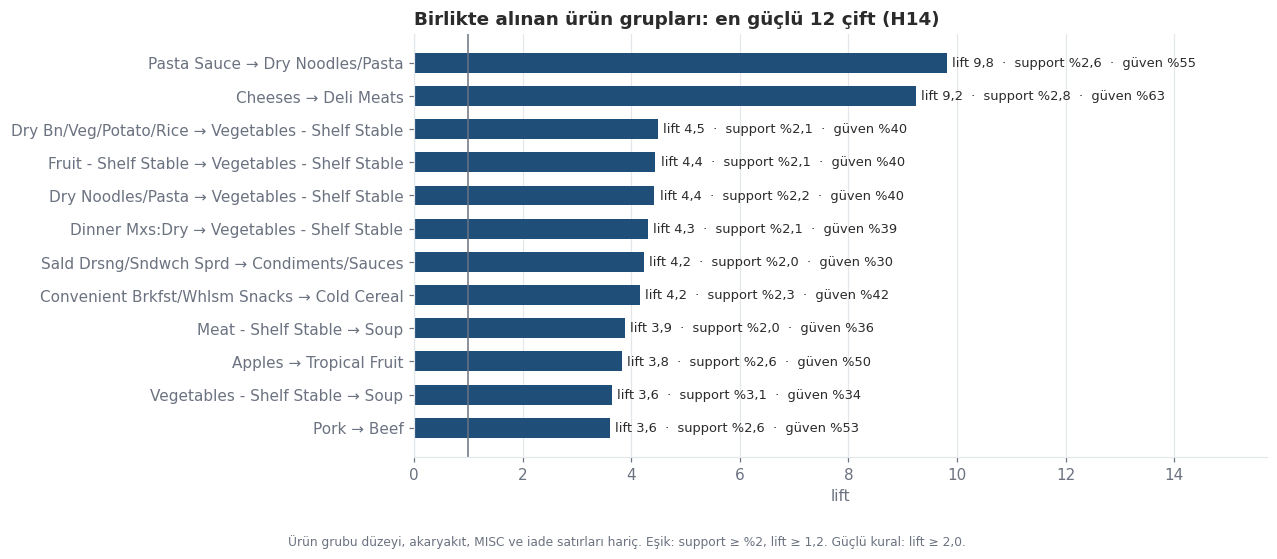

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

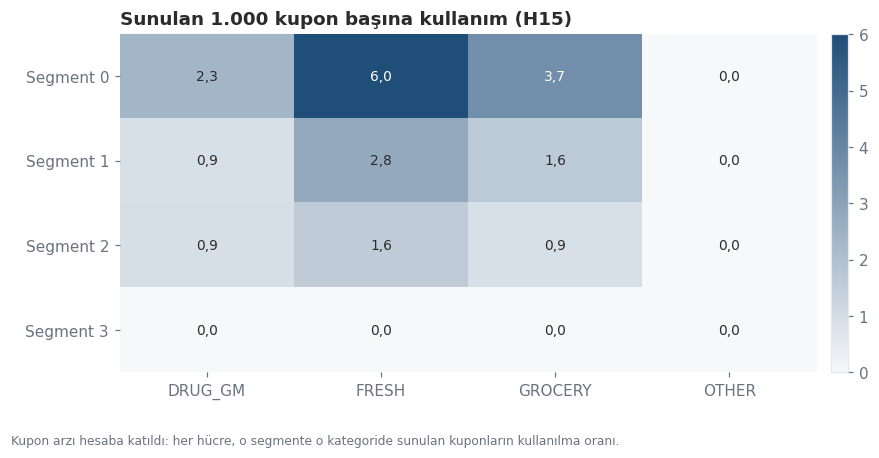

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
#@title D3. Görseller (H14, H15) { display-mode: "form" }
pairs_plot = association_rules_out.rename(columns={"antecedents": "antecedent", "consequents": "consequent"}).copy()
pairs_plot["pair"] = pairs_plot.apply(lambda r: " | ".join(sorted([r["antecedent"], r["consequent"]])), axis=1)
pairs_plot = pairs_plot.sort_values("confidence", ascending=False).drop_duplicates("pair")
top = pairs_plot.sort_values("lift", ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
labels = [f"{a.title()} → {c.title()}" for a, c in zip(top["antecedent"], top["consequent"])]
ax.barh(labels, top["lift"], color=ACCENT, height=0.6)
for y_i, (l, s, c) in enumerate(zip(top["lift"], top["support"], top["confidence"])):
    ax.text(l + 0.1, y_i, f"lift {fmt_num(l, 1)}  ·  support {fmt_pct(s, 1)}  ·  güven {fmt_pct(c)}", va="center", fontsize=8.5, color=INK)
ax.axvline(1, color=MUTED, linewidth=1)
ax.set_xlim(0, top["lift"].max() * 1.6); ax.grid(axis="y", visible=False); ax.set_xlabel("lift")
ax.set_title("Birlikte alınan ürün grupları: en güçlü 12 çift (H14)")
finish(fig, "d3_1_association_rules", f"Ürün grubu düzeyi, akaryakıt, MISC ve iade satırları hariç. Eşik: support ≥ {fmt_pct(MIN_SUPPORT)}, lift ≥ {fmt_num(MIN_LIFT, 1)}. Güçlü kural: lift ≥ {fmt_num(STRONG_LIFT, 1)}.")

per_k = rate_table * 1000
fig, ax = plt.subplots(figsize=(max(6, 1.4 * per_k.shape[1] + 3), 0.6 * per_k.shape[0] + 1.6))
im = ax.imshow(per_k.values, cmap=SEQ_CMAP, aspect="auto")
vmax = np.nanmax(per_k.values)
for i in range(per_k.shape[0]):
    for j in range(per_k.shape[1]):
        v = per_k.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, fmt_num(v, 1), ha="center", va="center", fontsize=9, color="white" if v > vmax * 0.55 else INK)
ax.set_xticks(range(per_k.shape[1]), per_k.columns)
ax.set_yticks(range(per_k.shape[0]), [f"Segment {s}" for s in per_k.index])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Sunulan 1.000 kupon başına kullanım (H15)")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
finish(fig, "d3_2_segment_coupon_category", "Kupon arzı hesaba katıldı: her hücre, o segmente o kategoride sunulan kuponların kullanılma oranı.")

## E. Özet: tek test ailesi
Birincil testi olan 12 ilişki (H1–H11 ve H15) tek ailede; Benjamini-Hochberg düzeltmesi bir kez uygulanır.
H12, H13 ve H14 betimleyici; aileye girmez, etki büyüklüğüyle raporlanır.

### Hipotez çerçevesi ve karar kuralı

Her hipotezde **H0: ilişki / fark yok**, **H1: ilişki / fark var**. p-değeri: H0 doğruysa bu kadar güçlü bir ilişkiyi tesadüfen görme ihtimali.
**Karar:** α = 0,05. Birincil testi olan 12 ilişki tek ailede **Benjamini-Hochberg** ile düzeltilir; `p_bh < 0,05` ise H0 reddedilir. Reddedilemezse "ilişki yok" değil, "kanıt yetersiz" denir. Her testte etki büyüklüğü de raporlanır.

| Hipotez | H0 | Birincil test | Neden bu test |
|---|---|---|---|
| H1–H3, H5, H6 | Değişken ile kupon kullanımı arasında ilişki yok | Kümelenmiş lojistik regresyon, Wald (A2). Mann-Whitney U yalnızca etki büyüklüğü için | Bir hane ortalama 4,5 kampanyada; standart hata hane ve kampanyaya göre kümelenir. Değişkenler birlikte modellenir, birbirinin etkisini taşımaz |
| H4 | Kupondaki ürünü önceden almak kullanımı etkilemiyor | Aynı model (A2); ki-kare ve Cramér's V etki için | Aynı gerekçe |
| H7 | Kampanya tipleri arasında kullanım farkı yok | Aynı model, iki tip katsayısı birlikte Wald | Tip yalnızca 30 kampanyadan tahmin edilir |
| H8 | Segmentler arasında kullanım farkı yok | Ki-kare, hane düzeyinde permütasyon (999) | Hane tekrarı; etiketler haneler arasında karıştırılır |
| H9–H11 | Değişken gelecek harcamayı açıklamıyor | PPML katsayısı = 0, HC1 dayanıklı z-testi; Spearman yön için | Harcama negatif değil ve çarpık; varyans ortalamayla büyür |
| H15 | Segmentin kupon kategorisi tercihi sunulan kupondan farklı değil | Poisson GLM, sunulan kupon offset, etkileşim LR testi | Çok kupon sunulan kategoride çok kullanım mekaniktir; offset bunu temizler |
| H12, H13, H14 | (test yok) | Kruskal-Wallis ε², Apriori lift | Betimleyici: segmentler veriden türetildi, p-değeri kendini doğrular |

In [ ]:
#@title E1. Hipotez sonuçları { display-mode: "form" }
h14_row = pd.DataFrame([{"hypothesis_id": "H14", "hypothesis": "H14 Birlikte alınan ürün grupları", "variable": "commodity_desc",
                         "test": "Apriori (betimleyici)", "summary": f"{n_pairs} benzersiz çift ({len(association_rules_out)} yönlü kural), güçlü çift (lift ≥ {STRONG_LIFT:g}): {n_strong_pairs}, en yüksek lift {association_rules_out['lift'].max():.2f}",
                         "effect": round(association_rules_out["lift"].max(), 3), "effect_type": "lift", "p_univariate": np.nan, "p_value": np.nan}])
hypothesis_results = pd.concat([results_a, results_b, results_h8, results_c, h14_row, results_h15], ignore_index=True)
hypothesis_results["is_descriptive"] = hypothesis_results["p_value"].isna()
family = ~hypothesis_results["is_descriptive"]
hypothesis_results["p_bh"] = np.nan
hypothesis_results.loc[family, "p_bh"] = multipletests(hypothesis_results.loc[family, "p_value"], method="fdr_bh")[1]
hypothesis_results["significant"] = hypothesis_results["p_bh"] < 0.05
hypothesis_results["order"] = hypothesis_results["hypothesis_id"].str[1:].astype(int)
hypothesis_results = hypothesis_results.sort_values(["order", "variable"]).drop(columns="order").reset_index(drop=True)
hypothesis_results[["hypothesis_id", "hypothesis", "test", "effect", "effect_type", "p_value", "p_bh", "significant", "is_descriptive"]]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,hypothesis_id,hypothesis,test,effect,effect_type,p_value,p_bh,significant,is_descriptive
0,H1,H1 Kupon kullanımı ~ sepet sayısı,Mann-Whitney U + kümelenmiş lojistik (birincil p),0.088,rank-biserial r,2.985652e-01,3.257075e-01,False,False
1,H2,H2 Kupon kullanımı ~ toplam harcama,Mann-Whitney U + kümelenmiş lojistik (birincil p),0.243,rank-biserial r,3.532602e-06,8.478244e-06,True,False
2,H3,H3 Kupon kullanımı ~ kuponlu sepet oranı,Mann-Whitney U + kümelenmiş lojistik (birincil p),0.497,rank-biserial r,2.645010e-35,1.058004e-34,True,False
3,H4,H4 Kupon kullanımı ~ kuponlu ürünü önceden alma,Ki-kare + kümelenmiş lojistik (birincil p),0.114,Cramér's V,3.316572e-04,6.633144e-04,True,False
4,H5,H5 Kupon kullanımı ~ son alışverişten geçen gün,Mann-Whitney U + kümelenmiş lojistik (birincil p),-0.116,rank-biserial r,4.171428e-02,5.005713e-02,False,False
5,H6,H6 Kupon kullanımı ~ indirim derinliği,Mann-Whitney U + kümelenmiş lojistik (birincil p),0.218,rank-biserial r,6.030132e-03,8.148747e-03,True,False
6,H7,H7 Kupon kullanımı ~ kampanya tipi,Ki-kare + kümelenmiş lojistik (birincil p),0.121,Cramér's V,5.061959e-12,1.518588e-11,True,False
7,H8,H8 Kupon kullanımı ~ segment,"Ki-kare, hane düzeyinde permütasyon (999)",0.094,Cramér's V,1.000000e-03,1.714286e-03,True,False
8,H9,H9 Gelecek harcama ~ geçmiş harcama,Spearman + PPML (birincil p),0.767,rho,0.000000e+00,0.000000e+00,True,False
9,H10,H10 Gelecek harcama ~ son 13 haftanın harcama payı,Spearman + PPML (birincil p),0.292,rho,6.580177e-95,3.948106e-94,True,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## F. Kupon modeli: tahmin testi ve çapraz kontrol

Soru: **kupon gönderilirse kullanılır mı?** Bu bölüm hipotez testi değil, **tahmin testidir**: model, hiç görmediği kampanyalarda kuponu kimin kullanacağını önceden bulabiliyor mu?
Bütün rakamlar Power BI ile aynı BigQuery tablolarından okunur: `ml_output.coupon_scores` (model puanı) ve `ml_output.kupon_takip` (kampanya öncesi / sonrası sepetler, churn ve geri dönüş bayrakları).

| Adım | Ne kontrol ediliyor |
|---|---|
| F1 | Test seti nasıl ayrılmış (hane mi, kampanya / zaman mı) |
| F2 | Test setinde ROC AUC, PR AUC, kuponların yarısıyla recall ve Wilson güven aralığı; rastgele seçim = %50 |
| F3 | Segment bazında recall: tek eşik ve segment eşiği (adil olan segment eşiği) |
| F4 | Churn ve geri dönüş karnesi: kupon kullanan ve kullanmayan düşüşteki hanelerin geri dönüşü, iki oran testi |

`kupon_takip` tanımları: A = kampanya başlangıcından 182–92 gün önce, B = son 91 gün, C = kampanya bitişinden sonraki 91 gün. **Düzenli:** A'da ≥ 8 sepet. **Düşüşte (churn):** düzenli ve B ≤ %70 × A. **Geri döndü:** düşüşte ve C ≥ %90 × A (yalnızca C penceresi veride varsa).

Model yarışı ve baz çizgiler (sabit tahmin, kampanya tipi, tek değişken, gradient boosting, C seçimi, bootstrap AUC aralığı, hane gruplu CV) **A3b ve A3c**'de; bu bölüm onları tekrarlamaz.

In [ ]:
#@title F1. BigQuery tablolarını oku ve bölme türünü kontrol et { display-mode: "form" }
cs = run_query(f"select household_key, campaign_id, score, is_test_set from `{PROJECT}.{ML_DATASET}.coupon_scores`")
kt = run_query(f"select * from `{PROJECT}.{ML_DATASET}.kupon_takip`")
kt = kt.merge(cs[["household_key", "campaign_id", "score"]], on=["household_key", "campaign_id"], how="left")

# Puanı olan satırlar; is_test_set BigQuery'den nullable gelir
kt_m = kt[kt["is_test_set"].notna()].copy()
kt_m["is_test_set"] = kt_m["is_test_set"].astype(bool)
kt_m["redeemed"] = kt_m["redeemed"].astype(bool)

split_check = kt_m.groupby("is_test_set").agg(
    satir=("campaign_id", "size"), hane=("household_key", "nunique"), kampanya=("campaign_id", "nunique"),
    ilk_baslangic=("start_day", "min"), son_baslangic=("start_day", "max"))
ortak_hane = len(set(kt_m.loc[kt_m["is_test_set"], "household_key"]) & set(kt_m.loc[~kt_m["is_test_set"], "household_key"]))
ortak_kampanya = len(set(kt_m.loc[kt_m["is_test_set"], "campaign_id"]) & set(kt_m.loc[~kt_m["is_test_set"], "campaign_id"]))
print(f"kupon_takip satırı: {len(kt)} | puanla eşleşmeyen: {kt['is_test_set'].isna().sum()}")
print(f"iki sette ortak hane: {ortak_hane} | ortak kampanya: {ortak_kampanya}")
print("Ortak kampanya 0 ve ortak hane > 0 ise bölme kampanya bazındadır (eski kampanyalarla eğitim, yenilerinde test).")
split_check

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

kupon_takip satırı: 7108 | puanla eşleşmeyen: 28
iki sette ortak hane: 1107 | ortak kampanya: 0
Ortak kampanya 0 ve ortak hane > 0 ise bölme kampanya bazındadır (eski kampanyalarla eğitim, yenilerinde test).


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,satir,hane,kampanya,ilk_baslangic,son_baslangic
is_test_set,,,,,
False,4982,1471,22,224,603
True,2098,1207,7,547,659


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
#@title F2. Test setinde skorlar: AUC, PR AUC, recall ve güven aralığı { display-mode: "form" }
te_bq_df = kt_m[kt_m["is_test_set"]].copy()
y_bq = te_bq_df["redeemed"].astype(int).to_numpy()
p_bq = te_bq_df["score"].to_numpy()

k_rec = int(((te_bq_df["yari"] == 1) & te_bq_df["redeemed"]).sum())
n_rec = int(te_bq_df["redeemed"].sum())
lo, hi = wilson_ci(k_rec, n_rec)
f2 = pd.Series({
    "test_gonderim": len(te_bq_df),
    "test_kullanim": n_rec,
    "ortalama_kullanim": round(y_bq.mean(), 3),
    "roc_auc": round(roc_auc_score(y_bq, p_bq), 3),
    "pr_auc": round(average_precision_score(y_bq, p_bq), 3),
    "recall_yarim_kupon": round(k_rec / n_rec, 3),
    "recall_%95_alt": round(float(lo), 3),
    "recall_%95_ust": round(float(hi), 3),
    "kullanim_orani_ust_yari": round(te_bq_df.loc[te_bq_df["yari"] == 1, "redeemed"].mean(), 3),
    "kullanim_orani_alt_yari": round(te_bq_df.loc[te_bq_df["yari"] == 2, "redeemed"].mean(), 3),
})
print("Kıyas noktası: rastgele seçimde recall = 0,50 ve ROC AUC = 0,50.")
f2

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Kıyas noktası: rastgele seçimde recall = 0,50 ve ROC AUC = 0,50.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,0
test_gonderim,2098.000
test_kullanim,304.000
ortalama_kullanim,0.145
roc_auc,0.801
pr_auc,0.468
recall_yarim_kupon,0.862
recall_%95_alt,0.819
recall_%95_ust,0.896
kullanim_orani_ust_yari,0.250
kullanim_orani_alt_yari,0.040


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
#@title F3. Segment bazında recall: tek eşik ve segment eşiği { display-mode: "form" }
d = te_bq_df.copy()
d["segment_adi"] = d["segment_adi"].fillna("Segmentsiz")
# Segment eşiği: her segmentte kuponların yarısı (BigQuery NTILE(2) gibi, tek sayıda fazlası üst yarıya)
d["sira"] = d.groupby("segment_adi")["score"].rank(method="first", ascending=False)
d["seg_n"] = d.groupby("segment_adi")["score"].transform("size")
d["seg_yari"] = np.where(d["sira"] <= np.ceil(d["seg_n"] / 2), 1, 2)

rows = []
for seg, g in list(d.groupby("segment_adi")) + [("Toplam", d)]:
    n = int(g["redeemed"].sum())
    k_tek = int((g["redeemed"] & (g["yari"] == 1)).sum())
    k_seg = int((g["redeemed"] & ((g["seg_yari"] if seg != "Toplam" else g["yari"]) == 1)).sum())
    lo, hi = wilson_ci(k_seg, n) if n > 0 else (np.nan, np.nan)
    rows.append({"segment": seg, "kullanim_n": n,
                 "ust_yaridaki_kupon_payi": round((g["yari"] == 1).mean(), 3),
                 "recall_tek_esik": round(k_tek / n, 3) if n else np.nan,
                 "recall_segment_esik": round(k_seg / n, 3) if n else np.nan,
                 "%95_alt": round(float(lo), 3) if n else np.nan, "%95_ust": round(float(hi), 3) if n else np.nan,
                 "sunumda": "veri yetersiz" if n < 20 else "göster"})
recall_segment = pd.DataFrame(rows)
print("Sunumda segment eşiği kullanılır: her segmentte kuponların yarısı seçildiğinde kullananların ne kadarı yakalanıyor.")
print("Kullanım sayısı 20'nin altındaki segmentlerde oran gösterilmez.")
recall_segment

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sunumda segment eşiği kullanılır: her segmentte kuponların yarısı seçildiğinde kullananların ne kadarı yakalanıyor.
Kullanım sayısı 20'nin altındaki segmentlerde oran gösterilmez.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,segment,kullanim_n,ust_yaridaki_kupon_payi,recall_tek_esik,recall_segment_esik,%95_alt,%95_ust,sunumda
0,Pasif,1,0.000,0.000,1.000,0.207,1.000,veri yetersiz
1,Sadık büyük sepet,220,0.552,0.868,0.836,0.782,0.879,göster
2,Seyrek büyük alışveriş,7,0.211,0.429,0.714,0.359,0.918,veri yetersiz
3,Sık uğrayan küçük sepet,76,0.451,0.895,0.895,0.806,0.946,göster
4,Toplam,304,0.500,0.862,0.862,0.819,0.896,göster


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
#@title F4. Churn ve geri dönüş karnesi (geçmiş kampanyalar) { display-mode: "form" }
from statsmodels.stats.proportion import proportions_ztest

k = kt.copy()
for c in ["redeemed", "duzenli", "dususte"]:
    k[c] = k[c].astype(bool)
k["segment_adi"] = k["segment_adi"].fillna("Segmentsiz")

rows = []
for seg, g in list(k.groupby("segment_adi")) + [("Toplam", k)]:
    son = g[g["sonrasi_var"].astype(bool) & g["dususte"]]
    gd = son["geri_dondu"].astype(bool)
    n1, x1 = int(son["redeemed"].sum()), int((gd & son["redeemed"]).sum())
    n0, x0 = int((~son["redeemed"]).sum()), int((gd & ~son["redeemed"]).sum())
    p = proportions_ztest([x1, x0], [n1, n0])[1] if n1 >= 5 and n0 >= 5 else np.nan
    rows.append({"segment": seg, "gonderim": len(g),
                 "churn_orani": round(g["dususte"].sum() / max(g["duzenli"].sum(), 1), 3),
                 "kullanim_orani": round(g["redeemed"].mean(), 3),
                 "dususte_kullanim_orani": round(g.loc[g["dususte"], "redeemed"].mean(), 3) if g["dususte"].any() else np.nan,
                 "geri_donus_kullanan": round(x1 / n1, 3) if n1 else np.nan, "kullanan_n": n1,
                 "geri_donus_kullanmayan": round(x0 / n0, 3) if n0 else np.nan, "kullanmayan_n": n0,
                 "fark_puan": round((x1 / n1 - x0 / n0) * 100, 1) if n1 and n0 else np.nan,
                 "p_iki_oran": round(p, 3) if pd.notna(p) else np.nan})
churn_karne = pd.DataFrame(rows)
print("Geri dönüş farkı nedensel etki değildir: kuponu kullanan hane zaten daha istekli olabilir ve satırlar bağımsız değildir (aynı hane birden çok kampanyada).")
print("p ≥ 0,05 ise fark 'yön' olarak raporlanır; kesin etki deneme / kontrol kampanyasıyla ölçülür.")
churn_karne

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Geri dönüş farkı nedensel etki değildir: kuponu kullanan hane zaten daha istekli olabilir ve satırlar bağımsız değildir (aynı hane birden çok kampanyada).
p ≥ 0,05 ise fark 'yön' olarak raporlanır; kesin etki deneme / kontrol kampanyasıyla ölçülür.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,segment,gonderim,churn_orani,kullanim_orani,dususte_kullanim_orani,geri_donus_kullanan,kullanan_n,geri_donus_kullanmayan,kullanmayan_n,fark_puan,p_iki_oran
0,Pasif,43,0.550,0.023,0.000,NaN,0,0.000,16,NaN,NaN
1,Sadık büyük sepet,4104,0.195,0.149,0.099,0.340,53,0.305,456,3.5,0.604
2,Seyrek büyük alışveriş,367,0.660,0.057,0.055,0.000,5,0.060,116,-6.0,0.571
3,Sık uğrayan küçük sepet,2594,0.243,0.095,0.054,0.263,19,0.204,398,6.0,0.530
4,Toplam,7108,0.232,0.124,0.075,0.299,77,0.230,986,6.8,0.172


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## G. Sonuçları BigQuery'ye yaz
Power BI hesap yapmaz; bu tabloları okur. `model_metrics` uzun biçimde (task, model_variant, metric, value) yazılır; ML sayfası kartları bu tablodan filtreyle okunur. `chart_data` her hipotez grafiğinin hazır verisi: grup, sıra, değer, güven aralığı.
Dataset konumu dbt dataset'iyle aynı olmalı (EU); değilse hücre durur.

**Kupon skoru doğrulama tablosu (`model_dogrulama_nb`).** Power BI'daki `model_dogrulama` SQL ile kuruldu (farklı sütunlar: `grup`, `gonderim`, `kullanim`); üzerine yazılmasın diye bu notebook'un çıktısı ayrı adla yazılır. Power BI kampanya sayfası ("Tahmin doğru müşteriyi buluyor") bu tablodan okunur. Test kümesindeki (zaman bazlı ayrım: eğitimde görülmeyen son kampanyalar) satırlar, kapsam içinde skora göre ikiye bölünür: `yari = 1` skoru yüksek yarı. Her yarı için gönderilen kuponun ve kullanılan kuponun payı yazılır.
Segment adları Power BI'daki adlarla aynı olmalı (C2c hücresi profili kontrol eder).

In [ ]:
#@title G0. model_dogrulama: skor yarıları, gönderim ve kullanım payı (test kümesi) { display-mode: "form" }
SEG_NAMES = {0: "Sadık büyük sepet", 1: "Sık uğrayan küçük sepet", 2: "Seyrek büyük alışveriş", 3: "Pasif"}
val = coupon_scores.copy()
val["y"] = logit_df["y"].values                      # coupon_scores ve logit_df aynı satır sırasında
val = val[val["is_test_set"]].merge(household_segments, on="household_key", how="left")
val["segment_name"] = val["segment_id"].map(SEG_NAMES)

rows_v = []
scopes = [("Tüm haneler", val)] + [(name, val[val["segment_name"] == name]) for name in SEG_NAMES.values()]
for scope, d in scopes:
    if len(d) < 20 or d["y"].sum() == 0:
        continue
    half = (d["score"].rank(method="first", pct=True) > 0.5).astype(int)   # 1: skoru yüksek yarı
    for h in [0, 1]:
        m = half == h
        rows_v.append({"kapsam": scope, "yari": h, "n_gonderim": int(m.sum()), "n_kullanim": int(d.loc[m, "y"].sum()),
                       "gonderim_payi": m.mean(), "kullanim_payi": d.loc[m, "y"].sum() / d["y"].sum()})
model_dogrulama = pd.DataFrame(rows_v)
print(f"test kümesi: {len(val)} gönderim, {int(val['y'].sum())} kullanım")
model_dogrulama.round(3)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

test kümesi: 2098 gönderim, 304 kullanım

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,kapsam,yari,n_gonderim,n_kullanim,gonderim_payi,kullanim_payi
0,Tüm haneler,0,1049,42,0.500,0.138
1,Tüm haneler,1,1049,262,0.500,0.862
2,Sadık büyük sepet,0,656,36,0.500,0.161
3,Sadık büyük sepet,1,656,188,0.500,0.839
4,Sık uğrayan küçük sepet,0,341,9,0.499,0.123
5,Sık uğrayan küçük sepet,1,342,64,0.501,0.877
6,Seyrek büyük alışveriş,0,48,2,0.500,0.286
7,Seyrek büyük alışveriş,1,48,5,0.500,0.714


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
#@title G1. Sonuç tablolarını hazırla { display-mode: "form" }
rows = []
def add_rate_rows(df, group_col, hid, chart_id, order_col=None):
    g = df.groupby(group_col, dropna=False).agg(k=("redeemed", "sum"), n=("redeemed", "size"))
    if order_col is not None:
        g["sort_key"] = df.groupby(group_col, dropna=False)[order_col].median()
    else:
        g["sort_key"] = range(len(g))
    g = g.sort_values("sort_key").reset_index()
    low, high = wilson_ci(g["k"], g["n"])
    for i, r in g.iterrows():
        rows.append({"chart_id": chart_id, "hypothesis_id": hid, "group_label": str(r[group_col]), "group_order": i + 1,
                     "x_value": np.nan, "n": int(r["n"]), "value": r["k"] / r["n"], "ci_low": low[i], "ci_high": high[i],
                     "value_type": "kupon kullanım oranı", "detail": ""})

def add_mean_rows(df, x, y, hid, chart_id, bins, value_type):
    g = binned(df, x, y, bins=bins)
    for i, r in g.iterrows():
        rows.append({"chart_id": chart_id, "hypothesis_id": hid, "group_label": f"{i + 1}. dilim", "group_order": i + 1,
                     "x_value": r["x_mean"], "n": int(r["n"]), "value": r["y_mean"], "ci_low": r["y_mean"] - 1.96 * r["se"],
                     "ci_high": r["y_mean"] + 1.96 * r["se"], "value_type": value_type, "detail": x})

bucket_map = {"H1": ("basket_count_bucket", "pre_basket_count"), "H2": ("sales_value_bucket", "pre_sales_value"),
              "H3": ("coupon_ratio_bucket", "pre_coupon_basket_ratio"), "H5": ("recency_bucket", "days_since_last_purchase"),
              "H6": ("discount_depth_bucket", "pre_discount_depth")}
for hid, (bucket, raw) in bucket_map.items():
    add_rate_rows(test_df, bucket, hid, f"{hid.lower()}_by_bucket", order_col=raw)
add_rate_rows(test_df, "bought_coupon_product_before", "H4", "h4_bought_before")
add_rate_rows(test_df, "campaign_type", "H7", "h7_by_type")
camp_rows = test_df.groupby(["campaign_id", "campaign_type"])["redeemed"].agg(["sum", "size"]).reset_index()
low, high = wilson_ci(camp_rows["sum"], camp_rows["size"])
for i, r in camp_rows.iterrows():
    rows.append({"chart_id": "h7_by_campaign", "hypothesis_id": "H7", "group_label": str(r["campaign_id"]), "group_order": i + 1,
                 "x_value": np.nan, "n": int(r["size"]), "value": r["sum"] / r["size"], "ci_low": low[i], "ci_high": high[i],
                 "value_type": "kupon kullanım oranı", "detail": r["campaign_type"]})
add_rate_rows(h8_df, "segment_id", "H8", "h8_by_segment")
add_mean_rows(reg_df, "past_sales_w17", "future_sales", "H9", "h9_binscatter", 20, "ortalama gelecek harcama")
add_mean_rows(reg_df, "last_13w_sales_share_w17", "future_sales", "H10", "h10_binscatter", 10, "ortalama gelecek harcama")
add_mean_rows(reg_df, "private_brand_share_w17", "future_sales", "H11", "h11_binscatter", 10, "ortalama gelecek harcama")
for col, (hid, label) in segment_vars.items():
    m = cluster_df.groupby("segment_id")[col].agg(["mean", "std", "size"]).reset_index()
    for i, r in m.iterrows():
        se = r["std"] / np.sqrt(r["size"])
        rows.append({"chart_id": f"{hid.lower()}_{col}", "hypothesis_id": hid, "group_label": f"Segment {int(r['segment_id'])}",
                     "group_order": int(r["segment_id"]) + 1, "x_value": np.nan, "n": int(r["size"]), "value": r["mean"],
                     "ci_low": r["mean"] - 1.96 * se, "ci_high": r["mean"] + 1.96 * se, "value_type": "segment ortalaması", "detail": col})
chart_data = pd.DataFrame(rows)

coupon_odds_ratios = results_a2.reset_index().rename(columns={"index": "variable"})
coupon_odds_ratios["label"] = coupon_odds_ratios["variable"].map(lambda v: pretty.get(v, v.replace("C(campaign_type, Treatment(reference='TypeB'))[T.", "H7 Tip ").replace("]", " (TypeB'ye göre)")))

def to_long(df, task):
    d = df.rename(columns={"model": "model_variant"}).melt(id_vars="model_variant", var_name="metric", value_name="value")
    d["task"] = task
    return d[["task", "model_variant", "metric", "value"]]

model_metrics = pd.concat([to_long(model_metrics_lr, "Sınıflandırma"), to_long(model_metrics_reg, "Regresyon")], ignore_index=True)
model_metrics["value"] = model_metrics["value"].astype(float)

gi = np.linspace(0, len(share_targeted) - 1, 101).astype(int)
gains_curve = pd.DataFrame({"share_targeted": np.asarray(share_targeted)[gi], "share_captured": share_captured.values[gi]})
calibration = calib.reset_index()
k_selection = k_table.copy()

# Günlük ziyaret aralığı (aynı gün birden çok sepet tek ziyaret sayılır): Power BI "Hane yolculuğu" sayfası için
household_visit_gaps = run_query(f"""
    with d as (
        select household_key, day as day_no, sum(sales_value) as sales_value, count(distinct basket_id) as basket_count
        from `{PROJECT}.{DATASET}.stg_raw__transaction_data`
        group by household_key, day
    )
    select household_key, day_no, sales_value, basket_count,
           day_no - lag(day_no) over (partition by household_key order by day_no) as gap_days
    from d
""")

outputs = {
    "household_segments": household_segments,
    "hypothesis_results": hypothesis_results,
    "coupon_odds_ratios": coupon_odds_ratios,
    "coupon_scores": coupon_scores,
    "clv_predictions": clv_predictions,
    "association_rules": association_rules_out,
    "segment_coupon_category": segment_coupon_category,
    "chart_data": chart_data,
    "model_metrics": model_metrics,
    "k_selection": k_selection,
    "gains_curve": gains_curve,
    "calibration": calibration,
    "household_visit_gaps": household_visit_gaps,
    "model_dogrulama_nb": model_dogrulama,   # SQL ile kurulan model_dogrulama (Power BI) korunur
}
pd.Series({name: len(df) for name, df in outputs.items()})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,0
household_segments,2500
hypothesis_results,17
coupon_odds_ratios,8
coupon_scores,7080
clv_predictions,2390
association_rules,670
segment_coupon_category,16
chart_data,119
model_metrics,52
k_selection,7


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
#@title G2. BigQuery'ye yaz { display-mode: "form" }
# Yanlışlıkla çalıştırılırsa ml_output tabloları WRITE_TRUNCATE ile silinip yeniden yazılır. Bilerek True yapın.
WRITE_TO_BQ = False

if WRITE_TO_BQ:
    source_location = client.get_dataset(f"{PROJECT}.{DATASET}").location
    target = bigquery.Dataset(f"{PROJECT}.{ML_DATASET}")
    target.location = source_location
    target = client.create_dataset(target, exists_ok=True)
    assert target.location == source_location, f"ml_output konumu {target.location}, dbt dataset konumu {source_location}: aynı olmalı"

    job_config = bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE")
    for name, df in outputs.items():
        client.load_table_from_dataframe(df.reset_index(drop=True), f"{PROJECT}.{ML_DATASET}.{name}", job_config=job_config).result()

    run_query(f"select table_id, row_count from `{PROJECT}.{ML_DATASET}.__TABLES__` order by table_id")
else:
    print("WRITE_TO_BQ = False: BigQuery'ye yazılmadı. Yazılacak tablolar:", ", ".join(outputs))

WRITE_TO_BQ = False: BigQuery'ye yazılmadı. Yazılacak tablolar: household_segments, hypothesis_results, coupon_odds_ratios, coupon_scores, clv_predictions, association_rules, segment_coupon_category, chart_data, model_metrics, k_selection, gains_curve, calibration, household_visit_gaps, model_dogrulama_nb


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Son tablo, `ml_output`'taki tabloların satır sayılarını gösterir (bu notebook 14 tablo yazar: v5'teki 8 + 5 yeni (v6) + model_dogrulama; `household_weekly` ve `household_order_gaps` ayrı SQL ile kurulmuştu, onlar da listede görünür); G1'deki sayılarla aynı olmalı. Ardından dbt'de segment tablolarına bağlı `rpt_` modelleri yeniden kurulur.